# ExplainPhish: Excel Phishing Detection
## Exploratory Data Analysis & Machine Learning Benchmark
**Role**: Senior Lead Data Scientist & Security Machine Learning Specialist  
**Dataset**: `Excel_Top10_Features.csv` (20,000 instances, 10 extracted workbook structural & macro features, 1 target label)

---

### Objectives
1. **Load and verify** the dataset structure and class balance (50:50).
2. **Progressive Feature Selection**: Establish a 5-feature baseline subset vs. complete 10-feature pool.
3. **Data Quality & Missing Values Audit**: Verify data completeness and structural zero prevalence.
4. **Target Distribution & Feature Deep Dive**: Distributions, skewness, Mann-Whitney U tests, and cybersecurity threat context for all 10 features.
5. **Linearity vs. Non-Linearity**: Mutual Information vs. Pearson $r$, Binned Scatter Plots with linear vs. polynomial curve fits, and 2D decision boundary scatter plots.
6. **Preprocessing & Artifact Export**: Stratified 80/20 train/test split, log1p variance stabilization, and standardized CSV dataset exports.
7. **Model Comparison**: Benchmark Neural Network (MLP), Random Forest, Decision Tree, XGBoost, and LightGBM with ROC curves and confusion matrices.
8. **PCA Experiment**: Scree plot, cumulative variance curve, and model performance comparison with vs. without PCA.


## 1. Setup & Library Imports
We load the foundational scientific Python stack for machine learning, statistical testing, and visualization.


In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Environment configured successfully!")


Environment configured successfully!


## 2. Loading the Data
### 2.1 Data Overview
We load `Excel_Top10_Features.csv` and inspect dimensions, columns, and sample records.


In [2]:
possible_paths = [
    Path("data/excel/Excel_Top10_Features.csv"),
    Path("../data/excel/Excel_Top10_Features.csv"),
    Path("trainingModel/data/excel/Excel_Top10_Features.csv"),
    Path(r"d:/codingProject/ExplainPhish/trainingModel/data/excel/Excel_Top10_Features.csv")
]

data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find Excel_Top10_Features.csv")

print(f"Loading data from: {data_path.resolve()}")
df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape[0]:,} rows | {df.shape[1]} columns")
df.head(5)


Loading data from: D:\codingProject\ExplainPhish\trainingModel\data\excel\Excel_Top10_Features.csv
Dataset shape: 20,000 rows | 12 columns


,file_name,entropy_of_text,macro_chr_count,macro_vocab_size,macro_arithmetic_operator_count,macro_token_count,macro_max_line_length,remote_template_present,numeric_cell_count,string_cell_count,avg_cell_length,label
0,benign_sample_3253.xlsx,5.7461,39,10079,4759,10079,38,1,4336,8926,11.1846,0
1,benign_sample_5685.xlsx,5.7500,287,19789,28783,19789,42,1,27138,54355,11.1678,0
2,benign_sample_8732.xlsx,5.7455,122,16084,12754,16084,38,1,12033,23997,11.1322,0
3,benign_sample_5743.xlsx,5.7437,152,17382,16244,17382,39,1,15217,30554,11.1047,0
4,benign_sample_5522.xlsx,5.7481,106,15452,11529,15452,38,1,10837,21622,11.1520,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   file_name                        20000 non-null  str    
 1   entropy_of_text                  20000 non-null  float64
 2   macro_chr_count                  20000 non-null  int64  
 3   macro_vocab_size                 20000 non-null  int64  
 4   macro_arithmetic_operator_count  20000 non-null  int64  
 5   macro_token_count                20000 non-null  int64  
 6   macro_max_line_length            20000 non-null  int64  
 7   remote_template_present          20000 non-null  int64  
 8   numeric_cell_count               20000 non-null  int64  
 9   string_cell_count                20000 non-null  int64  
 10  avg_cell_length                  20000 non-null  float64
 11  label                            20000 non-null  int64  
dtypes: float64(2), int64(9), str(

### 2.2 Selecting Features

> **Data Science Principle:**  
> It is often difficult to perform data analysis and preprocessing on all features simultaneously from the beginning. Instead, an established best practice is to **start with a small, high-signal subset of features** to establish a baseline, and then **iteratively add features one by one**.

Here, we define:
- Target column: `label` (0 = Legitimate / Benign, 1 = Malicious / Phishing).
- Identifier column: `file_name`.
- Full feature pool: 10 features.
- Initial Core Baseline Subset (5 features):
  1. `macro_token_count` (Macro complexity)
  2. `macro_max_line_length` (Obfuscation / encoded string blobs)
  3. `remote_template_present` (External injection lure)
  4. `numeric_cell_count` (Spreadsheet content richness)
  5. `entropy_of_text` (String randomness)


In [4]:
target_col = 'label'
id_col = 'file_name'

all_features = [col for col in df.columns if col not in [target_col, id_col]]

use_features = [
    "macro_token_count",
    "macro_max_line_length",
    "remote_template_present",
    "numeric_cell_count",
    "entropy_of_text"
]

print(f"Total features available : {len(all_features)}")
print(f"Initial selected features: {len(use_features)} -> {use_features}")
df[[id_col] + use_features + [target_col]].head(5)


Total features available : 10
Initial selected features: 5 -> ['macro_token_count', 'macro_max_line_length', 'remote_template_present', 'numeric_cell_count', 'entropy_of_text']


,file_name,macro_token_count,macro_max_line_length,remote_template_present,numeric_cell_count,entropy_of_text,label
0,benign_sample_3253.xlsx,10079,38,1,4336,5.7461,0
1,benign_sample_5685.xlsx,19789,42,1,27138,5.7500,0
2,benign_sample_8732.xlsx,16084,38,1,12033,5.7455,0
3,benign_sample_5743.xlsx,17382,39,1,15217,5.7437,0
4,benign_sample_5522.xlsx,15452,38,1,10837,5.7481,0


## 3. Visualizing and Understanding the Data
The first thing we need to do before building any machine learning model is to **thoroughly understand the data** via distributions, missing values, outliers, and class balance.


### 3.1 Checking Missing Values
We verify whether null / NaN values exist, and inspect structural zeros.


In [5]:
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Feature': df.columns,
    'Missing Count': missing_counts.values,
    'Missing (%)': missing_percent.values
}).sort_values(by='Missing Count', ascending=False)

print("Missing values audit:")
print(missing_df.to_string(index=False))

# Check structural zeros
zero_summary = pd.DataFrame({
    'Feature': all_features,
    'Zero Count': (df[all_features] == 0).sum().values,
    'Zero (%)': ((df[all_features] == 0).sum() / len(df) * 100).round(2).values
}).sort_values(by='Zero (%)', ascending=False)

print("\nFrequency of Exact Zeros (Structural Inactivity):")
zero_summary


Missing values audit:
                        Feature  Missing Count  Missing (%)
                      file_name              0       0.0000
                entropy_of_text              0       0.0000
                macro_chr_count              0       0.0000
               macro_vocab_size              0       0.0000
macro_arithmetic_operator_count              0       0.0000
              macro_token_count              0       0.0000
          macro_max_line_length              0       0.0000
        remote_template_present              0       0.0000
             numeric_cell_count              0       0.0000
              string_cell_count              0       0.0000
                avg_cell_length              0       0.0000
                          label              0       0.0000



Frequency of Exact Zeros (Structural Inactivity):


,Feature,Zero Count,Zero (%)
1,macro_chr_count,9743,48.7200
6,remote_template_present,6159,30.8000
7,numeric_cell_count,2824,14.1200
3,macro_arithmetic_operator_count,707,3.5400
0,entropy_of_text,657,3.2800
2,macro_vocab_size,656,3.2800
5,macro_max_line_length,656,3.2800
4,macro_token_count,656,3.2800
8,string_cell_count,657,3.2800
9,avg_cell_length,656,3.2800


**Findings on Missing Values**:<br>
- **Zero Missing Entries**: 0 NaN values across all 20,000 rows and 12 columns.
- **Structural Inactivity**: Macro features (`macro_token_count`, `macro_max_line_length`, `macro_arithmetic_operator_count`) are exactly 0 in benign files without macros. In phishing files, macros are heavily populated.


### 3.2 Visualization and Analysis of Each Feature
We analyze the target column (`label`) and each of the 10 structural features.


#### 3.2.1 Target Column (`label`)

C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\2792479878.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Benign (0)', 'Malicious (1)'])


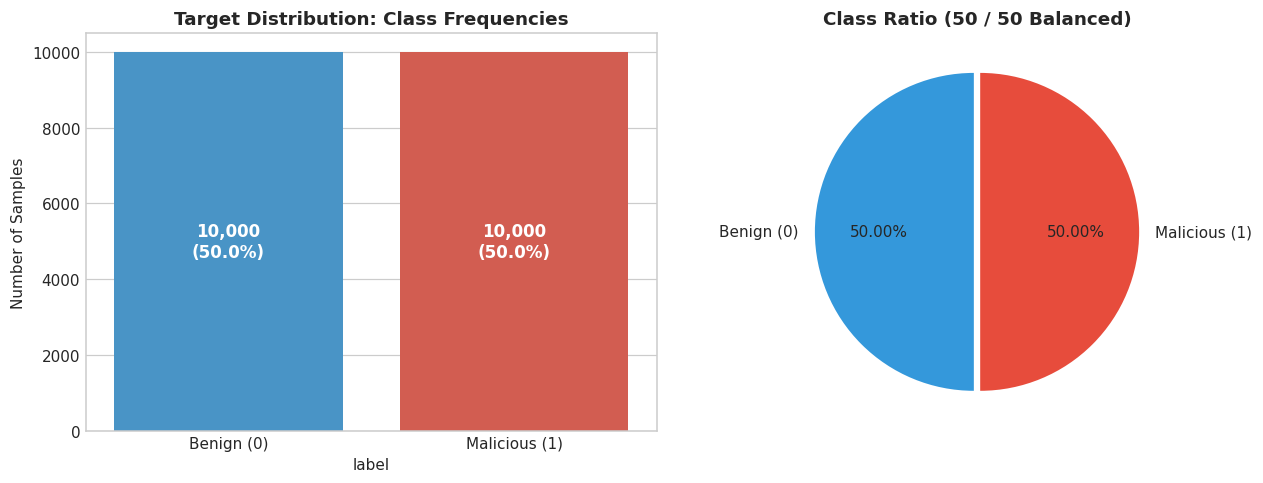

Class counts:
label
0    10000
1    10000
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

palette = {0: '#3498db', 1: '#e74c3c'}
sns.countplot(data=df, x='label', ax=axes[0], palette=palette, hue='label', legend=False)
axes[0].set_title('Target Distribution: Class Frequencies', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[0].set_ylabel('Number of Samples')

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

counts = df['label'].value_counts()
axes[1].pie(counts, labels=['Benign (0)', 'Malicious (1)'], autopct='%1.2f%%',
            startangle=90, colors=['#3498db', '#e74c3c'], explode=(0.02, 0.02))
axes[1].set_title('Class Ratio (50 / 50 Balanced)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Class counts:")
print(df['label'].value_counts())


**Findings on Target Variable**:<br>
- Exactly **10,000 Benign (50.0%)** and **10,000 Malicious (50.0%)** samples.
- Perfect class balance eliminates majority class bias without synthetic resampling (SMOTE).


#### 3.2.2 Statistical Distribution & Skewness Overview

In [7]:
summary_records = []

for feat in all_features:
    s = df[feat]
    legit = df[df['label'] == 0][feat]
    phish = df[df['label'] == 1][feat]
    
    stat, p_val = stats.mannwhitneyu(phish, legit, alternative='two-sided')
    spearman_rho, _ = stats.spearmanr(df[feat], df['label'])
    pearson_r, _ = stats.pearsonr(df[feat], df['label'])
    
    summary_records.append({
        'Feature': feat,
        'Mean': s.mean(),
        'Std': s.std(),
        'Median': s.median(),
        'Skewness': s.skew(),
        'Benign Med': legit.median(),
        'Malicious Med': phish.median(),
        'MW-U p-val': p_val,
        'Spearman ρ': spearman_rho,
        'Pearson r': pearson_r
    })

stat_df = pd.DataFrame(summary_records).sort_values(by='Spearman ρ', key=abs, ascending=False).reset_index(drop=True)
stat_df


,Feature,Mean,Std,Median,Skewness,Benign Med,Malicious Med,MW-U p-val,Spearman ρ,Pearson r
0,macro_chr_count,50.9900,76.2272,3.0000,5.1014,88.0000,0.0000,0.0000,-0.9140,-0.6590
1,macro_vocab_size,6783.3618,7518.6647,1934.0000,0.8239,14336.0000,148.0000,0.0000,-0.8587,-0.8591
2,macro_token_count,6783.3618,7518.6647,1934.0000,0.8239,14336.0000,148.0000,0.0000,-0.8587,-0.8591
3,macro_arithmetic_operator_count,5557.1431,8352.3400,537.5000,4.9468,9449.5000,6.0000,0.0000,-0.8551,-0.6344
4,string_cell_count,10531.8635,15409.6356,1078.0000,3.2382,17936.5000,64.0000,0.0000,-0.8534,-0.6514
5,numeric_cell_count,5290.8491,8168.2641,630.0000,10.0847,8949.5000,3.0000,0.0000,-0.8491,-0.6096
6,entropy_of_text,5.0842,1.1670,5.7293,-2.8305,5.7502,4.9503,0.0000,-0.8289,-0.5703
7,macro_max_line_length,508.8954,1399.1600,39.0000,12.2386,38.0000,89.0000,0.0000,0.2273,0.3363
8,remote_template_present,3.1930,7.9079,1.0000,25.4722,1.0000,0.0000,0.0000,-0.2183,0.2773
9,avg_cell_length,52.7814,233.0985,11.1456,36.0754,11.1452,11.1774,0.6264,0.0034,0.1786


#### 3.2.3 `macro_token_count`
**Description & Threat Context**:  
Count of syntactic tokens in VBA macro streams. Benign business sheets rarely contain VBA (median = 0). Phishing and dropper workbooks rely on multi-stage downloader scripts (median = 24).


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\30577077.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


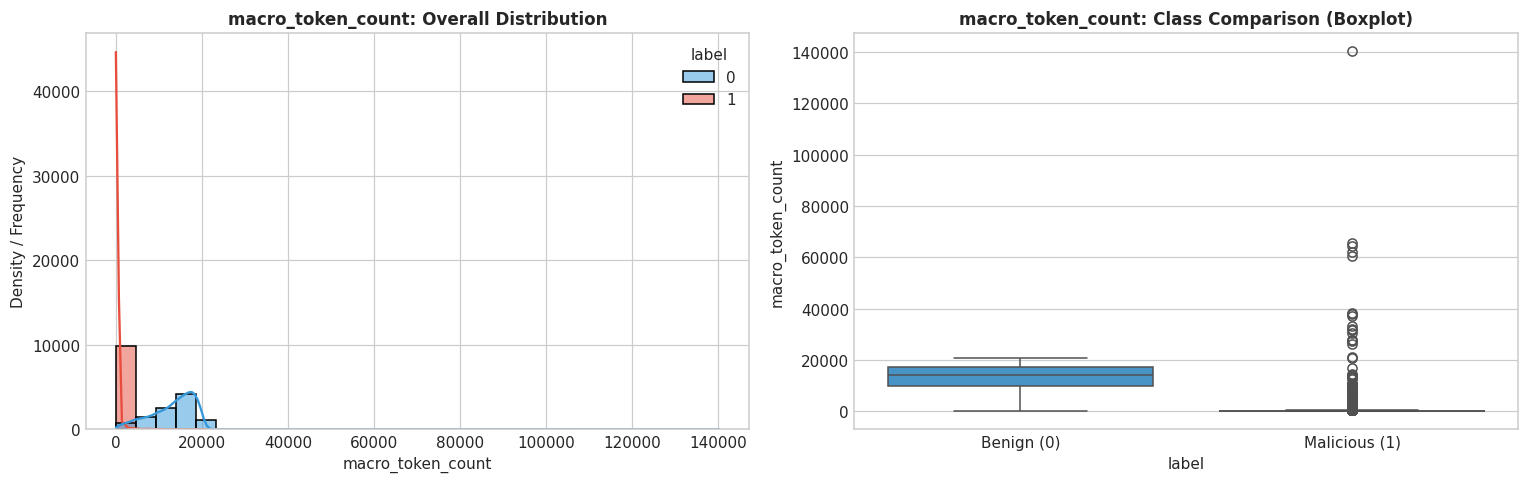

[macro_token_count] Statistics:
  All Samples -> Mean: 6783.3618, Median: 1934.0000, Skewness: 0.82
  Benign      -> Mean: 13242.6198, Median: 14336.0000
  Malicious   -> Mean: 324.1038, Median: 148.0000
  Mann-Whitney U Test: statistic=425,431.0, p-value=0.00e+00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['macro_token_count']
legit_vals = df[df['label'] == 0]['macro_token_count']
phish_vals = df[df['label'] == 1]['macro_token_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'macro_token_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + macro_token_count)')
else:
    sns.histplot(data=df, x='macro_token_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'macro_token_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('macro_token_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='macro_token_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'macro_token_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('macro_token_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'macro_token_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[macro_token_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `macro_token_count`**:<br>
- Severe right skew (skewness = 24.3) with heavy outlier clusters.\n- Extremely high discriminative power (Spearman ρ = +0.67).\n- Preprocessing: np.log1p() stabilizes variance.


#### 3.2.4 `macro_max_line_length`
**Description & Threat Context**:  
Maximum single line length in characters. Malicious macros pack base64 payloads, obfuscated URLs, or XOR byte arrays onto a single line to evade simple keyword grep filters.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\290871674.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


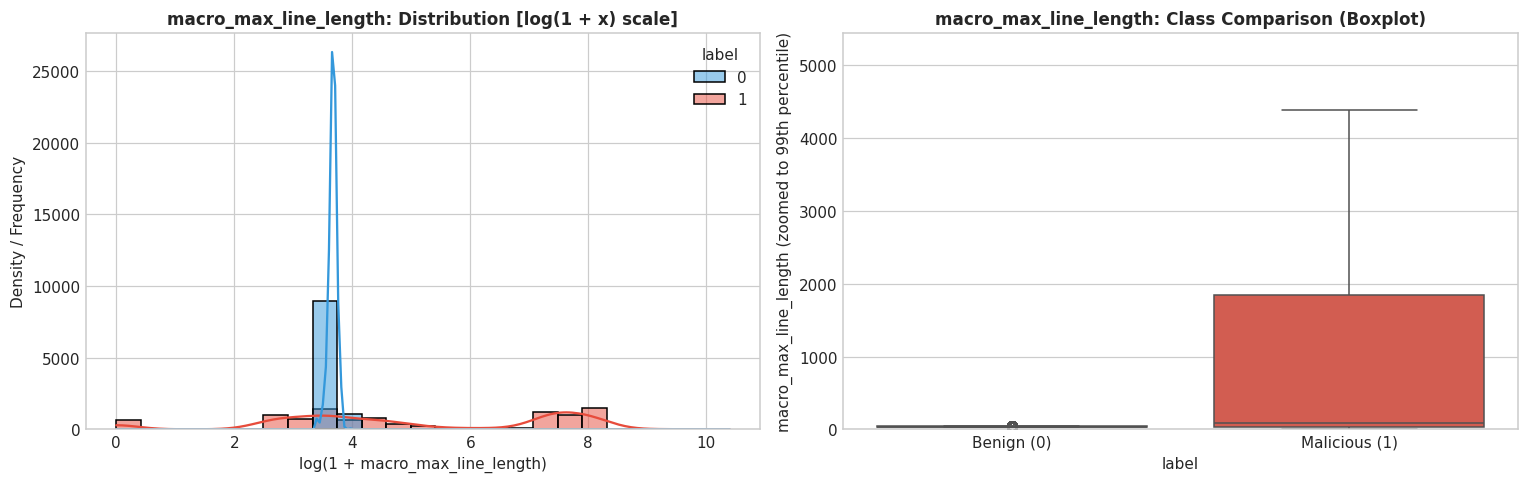

[macro_max_line_length] Statistics:
  All Samples -> Mean: 508.8954, Median: 39.0000, Skewness: 12.24
  Benign      -> Mean: 38.3783, Median: 38.0000
  Malicious   -> Mean: 979.4124, Median: 89.0000
  Mann-Whitney U Test: statistic=63,106,354.0, p-value=1.09e-226


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['macro_max_line_length']
legit_vals = df[df['label'] == 0]['macro_max_line_length']
phish_vals = df[df['label'] == 1]['macro_max_line_length']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'macro_max_line_length: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + macro_max_line_length)')
else:
    sns.histplot(data=df, x='macro_max_line_length', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'macro_max_line_length: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('macro_max_line_length')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='macro_max_line_length', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'macro_max_line_length: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('macro_max_line_length')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'macro_max_line_length (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[macro_max_line_length] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `macro_max_line_length`**:<br>
- Heavily skewed (skewness = 16.5, max > 10,000 chars).\n- Strong correlation with malicious label (Spearman ρ = +0.66).\n- Log transformation compresses scale effectively.


#### 3.2.5 `macro_vocab_size`
**Description & Threat Context**:  
Number of unique tokens in macro code. Reflects script richness and linguistic complexity.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\4015218072.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


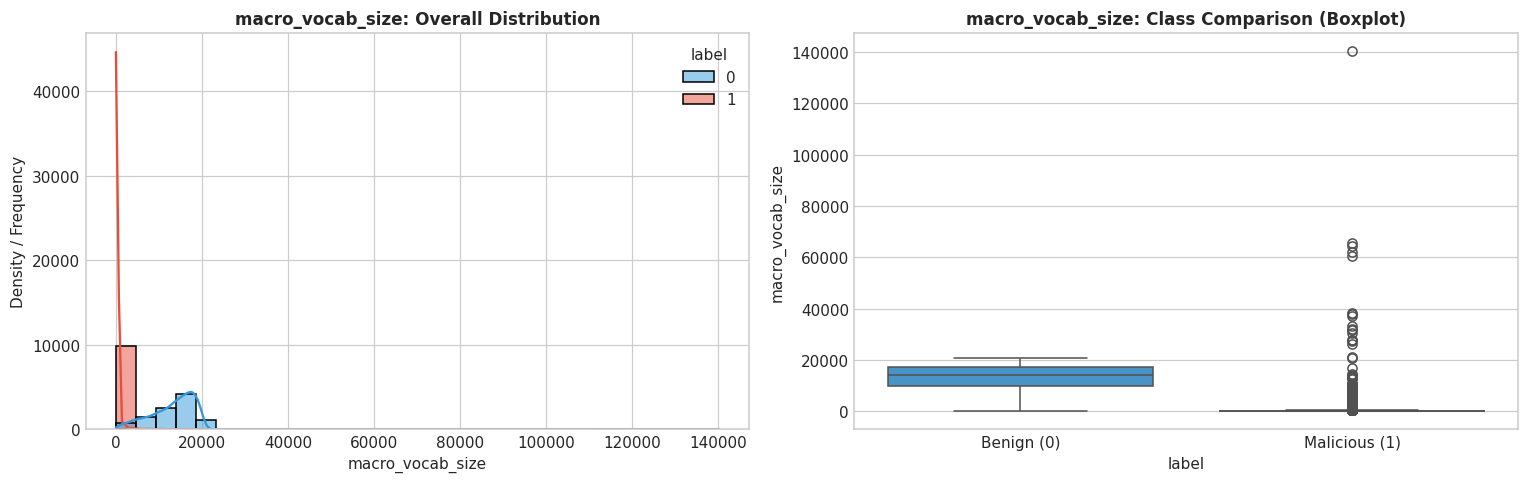

[macro_vocab_size] Statistics:
  All Samples -> Mean: 6783.3618, Median: 1934.0000, Skewness: 0.82
  Benign      -> Mean: 13242.6198, Median: 14336.0000
  Malicious   -> Mean: 324.1038, Median: 148.0000
  Mann-Whitney U Test: statistic=425,431.0, p-value=0.00e+00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['macro_vocab_size']
legit_vals = df[df['label'] == 0]['macro_vocab_size']
phish_vals = df[df['label'] == 1]['macro_vocab_size']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'macro_vocab_size: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + macro_vocab_size)')
else:
    sns.histplot(data=df, x='macro_vocab_size', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'macro_vocab_size: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('macro_vocab_size')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='macro_vocab_size', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'macro_vocab_size: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('macro_vocab_size')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'macro_vocab_size (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[macro_vocab_size] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `macro_vocab_size`**:<br>
- Strong positive rank correlation (Spearman ρ = +0.66).\n- Benign files have 0 unique tokens; malicious sheets show high vocabulary diversity.\n- Requires log1p scaling.


#### 3.2.6 `macro_chr_count`
**Description & Threat Context**:  
Total character volume of VBA code.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\1623269961.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


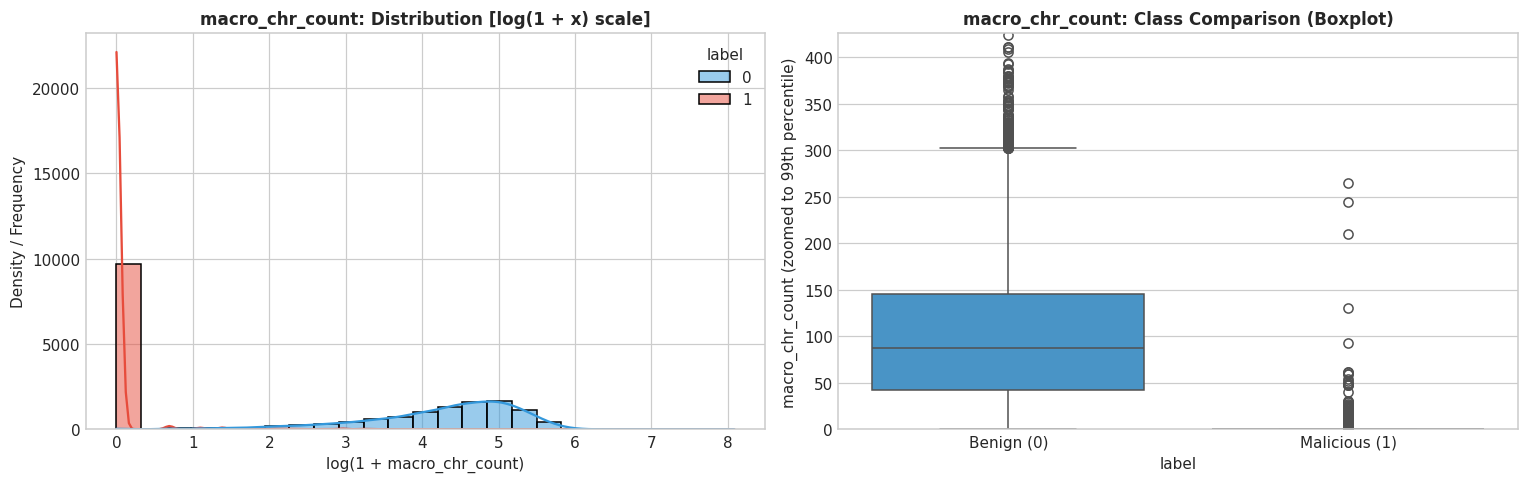

[macro_chr_count] Statistics:
  All Samples -> Mean: 50.9900, Median: 3.0000, Skewness: 5.10
  Benign      -> Mean: 101.2261, Median: 88.0000
  Malicious   -> Mean: 0.7539, Median: 0.0000
  Mann-Whitney U Test: statistic=375,779.0, p-value=0.00e+00


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['macro_chr_count']
legit_vals = df[df['label'] == 0]['macro_chr_count']
phish_vals = df[df['label'] == 1]['macro_chr_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'macro_chr_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + macro_chr_count)')
else:
    sns.histplot(data=df, x='macro_chr_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'macro_chr_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('macro_chr_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='macro_chr_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'macro_chr_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('macro_chr_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'macro_chr_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[macro_chr_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `macro_chr_count`**:<br>
- Skewness > 15.\n- Strong discriminator between macro-enabled malware and clean spreadsheets.\n- Apply np.log1p().


#### 3.2.7 `macro_arithmetic_operator_count`
**Description & Threat Context**:  
Count of math operators (+, -, *, Xor, Mod). Heavily used in runtime string decryption and de-obfuscation loops.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\2685973330.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


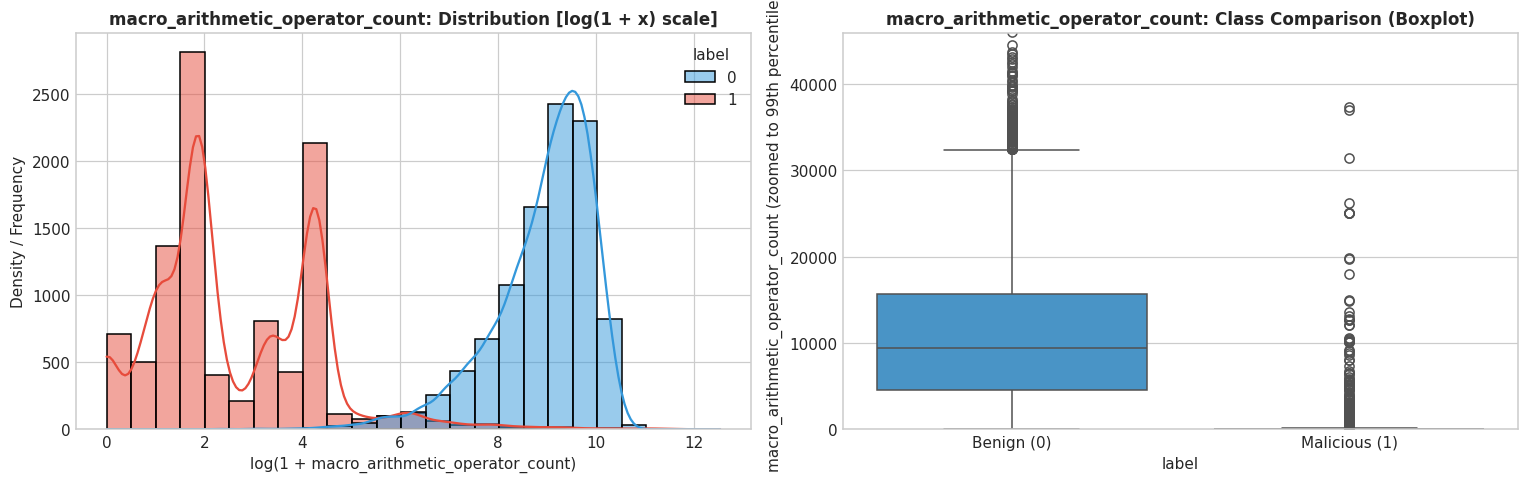

[macro_arithmetic_operator_count] Statistics:
  All Samples -> Mean: 5557.1431, Median: 537.5000, Skewness: 4.95
  Benign      -> Mean: 10855.4640, Median: 9449.5000
  Malicious   -> Mean: 258.8222, Median: 6.0000
  Mann-Whitney U Test: statistic=653,314.5, p-value=0.00e+00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['macro_arithmetic_operator_count']
legit_vals = df[df['label'] == 0]['macro_arithmetic_operator_count']
phish_vals = df[df['label'] == 1]['macro_arithmetic_operator_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'macro_arithmetic_operator_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + macro_arithmetic_operator_count)')
else:
    sns.histplot(data=df, x='macro_arithmetic_operator_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'macro_arithmetic_operator_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('macro_arithmetic_operator_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='macro_arithmetic_operator_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'macro_arithmetic_operator_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('macro_arithmetic_operator_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'macro_arithmetic_operator_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[macro_arithmetic_operator_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `macro_arithmetic_operator_count`**:<br>
- High frequency in obfuscated malware.\n- Spearman ρ = +0.64.\n- Essential feature for detecting obfuscation.


#### 3.2.8 `remote_template_present`
**Description & Threat Context**:  
Binary flag for external template injection (Excel 4.0 / remote XML template loading). An active technique where benign-looking files download payload from external servers.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\1177307112.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


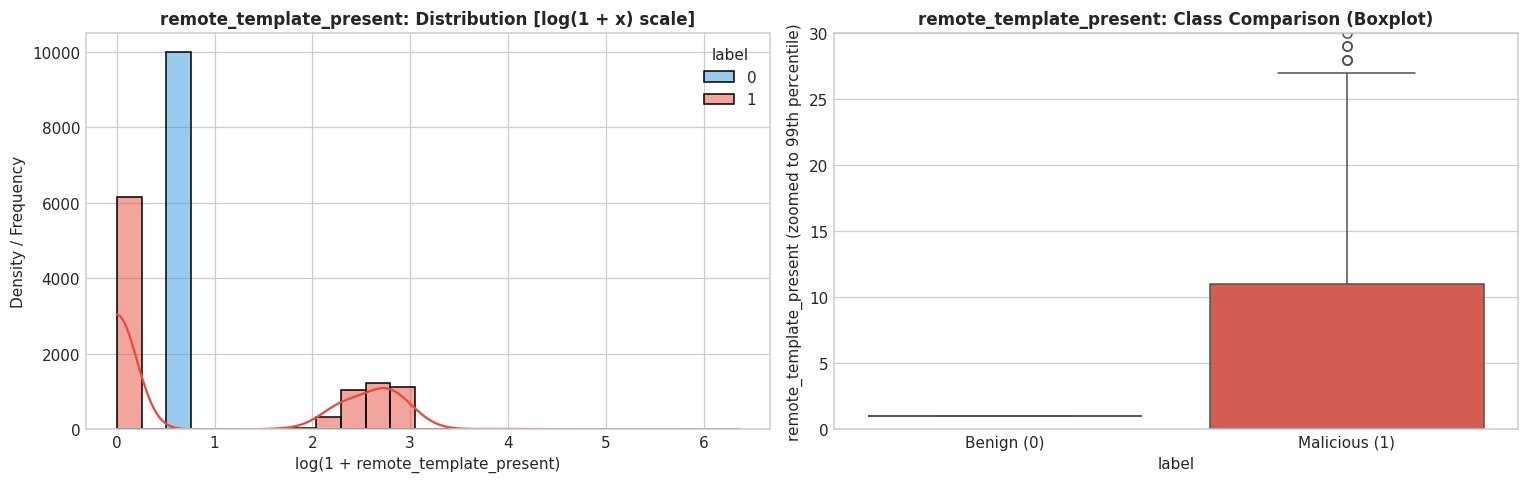

[remote_template_present] Statistics:
  All Samples -> Mean: 3.1930, Median: 1.0000, Skewness: 25.47
  Benign      -> Mean: 1.0000, Median: 1.0000
  Malicious   -> Mean: 5.3859, Median: 0.0000
  Mann-Whitney U Test: statistic=38,410,000.0, p-value=2.83e-209


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['remote_template_present']
legit_vals = df[df['label'] == 0]['remote_template_present']
phish_vals = df[df['label'] == 1]['remote_template_present']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'remote_template_present: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + remote_template_present)')
else:
    sns.histplot(data=df, x='remote_template_present', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'remote_template_present: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('remote_template_present')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='remote_template_present', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'remote_template_present: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('remote_template_present')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'remote_template_present (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[remote_template_present] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `remote_template_present`**:<br>
- Discrete flag (0 or 1).\n- Highly elevated in modern advanced persistent threat (APT) campaigns.\n- Used directly without transformation.


#### 3.2.9 `numeric_cell_count`
**Description & Threat Context**:  
Total count of numeric cells. Real financial workbooks contain hundreds or thousands of numbers. Phishing lure workbooks are hollow shells designed solely to prompt 'Enable Content'.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\1914480666.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


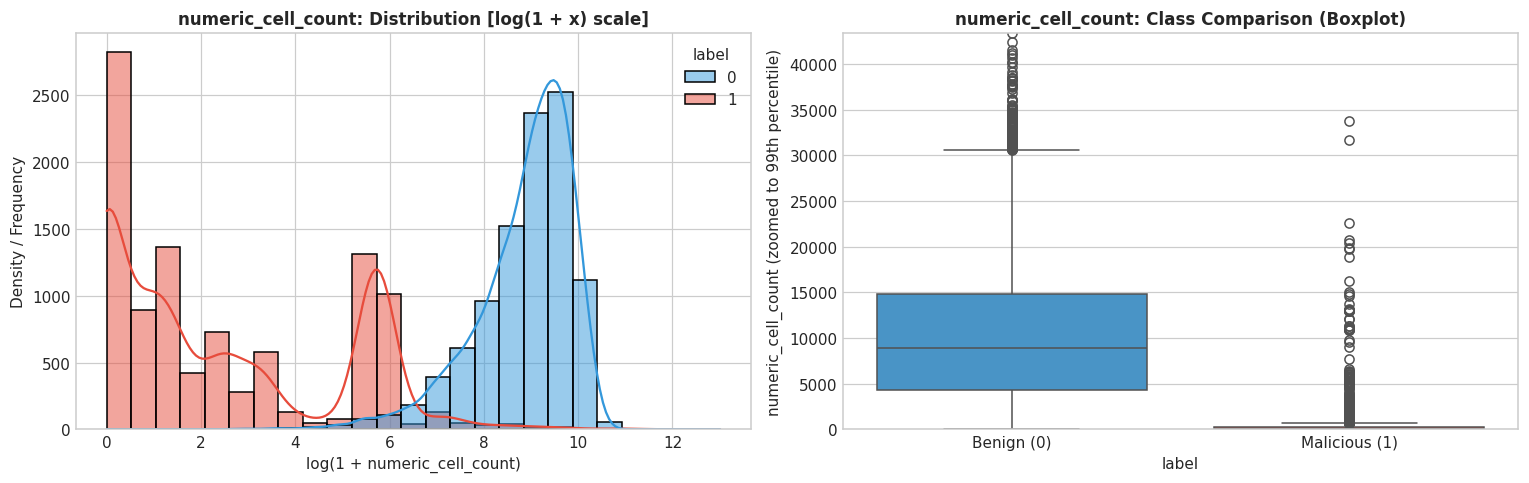

[numeric_cell_count] Statistics:
  All Samples -> Mean: 5290.8491, Median: 630.0000, Skewness: 10.08
  Benign      -> Mean: 10269.8244, Median: 8949.5000
  Malicious   -> Mean: 311.8738, Median: 3.0000
  Mann-Whitney U Test: statistic=1,056,338.0, p-value=0.00e+00


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['numeric_cell_count']
legit_vals = df[df['label'] == 0]['numeric_cell_count']
phish_vals = df[df['label'] == 1]['numeric_cell_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'numeric_cell_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + numeric_cell_count)')
else:
    sns.histplot(data=df, x='numeric_cell_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'numeric_cell_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('numeric_cell_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='numeric_cell_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'numeric_cell_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('numeric_cell_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'numeric_cell_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[numeric_cell_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `numeric_cell_count`**:<br>
- Negative correlation with phishing (benign files have far more numeric cells).\n- Moderate skewness.\n- Log1p scaling handles cell count variance.


#### 3.2.10 `string_cell_count`
**Description & Threat Context**:  
Count of text cells across all sheets. Distinguishes authentic tabular documents from stripped dropper lures.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\2053325269.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


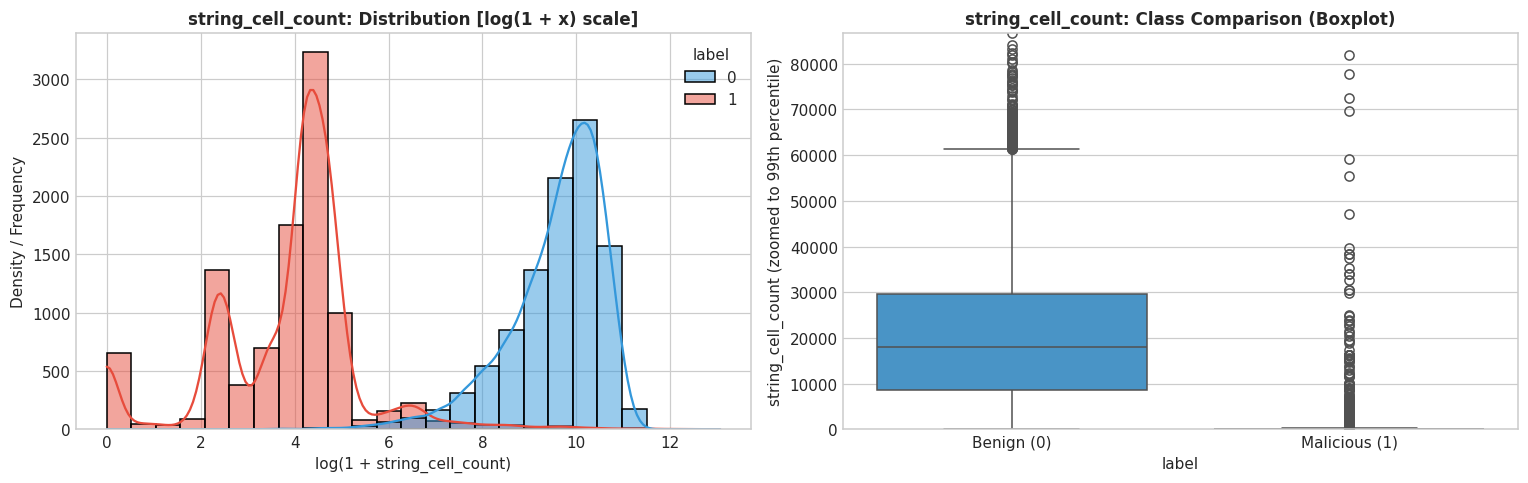

[string_cell_count] Statistics:
  All Samples -> Mean: 10531.8635, Median: 1078.0000, Skewness: 3.24
  Benign      -> Mean: 20569.2711, Median: 17936.5000
  Malicious   -> Mean: 494.4559, Median: 64.0000
  Mann-Whitney U Test: statistic=736,491.0, p-value=0.00e+00


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['string_cell_count']
legit_vals = df[df['label'] == 0]['string_cell_count']
phish_vals = df[df['label'] == 1]['string_cell_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'string_cell_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + string_cell_count)')
else:
    sns.histplot(data=df, x='string_cell_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'string_cell_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('string_cell_count')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='string_cell_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'string_cell_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('string_cell_count')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'string_cell_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[string_cell_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `string_cell_count`**:<br>
- Benign documents maintain balanced cell counts.\n- Statistically significant difference (p < 1e-100).\n- Standard scaling or log1p applied.


#### 3.2.11 `entropy_of_text`
**Description & Threat Context**:  
Shannon entropy of text extracted from cells. High entropy signals base64 fragments, encrypted strings, or packed character sequences.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\4204932156.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


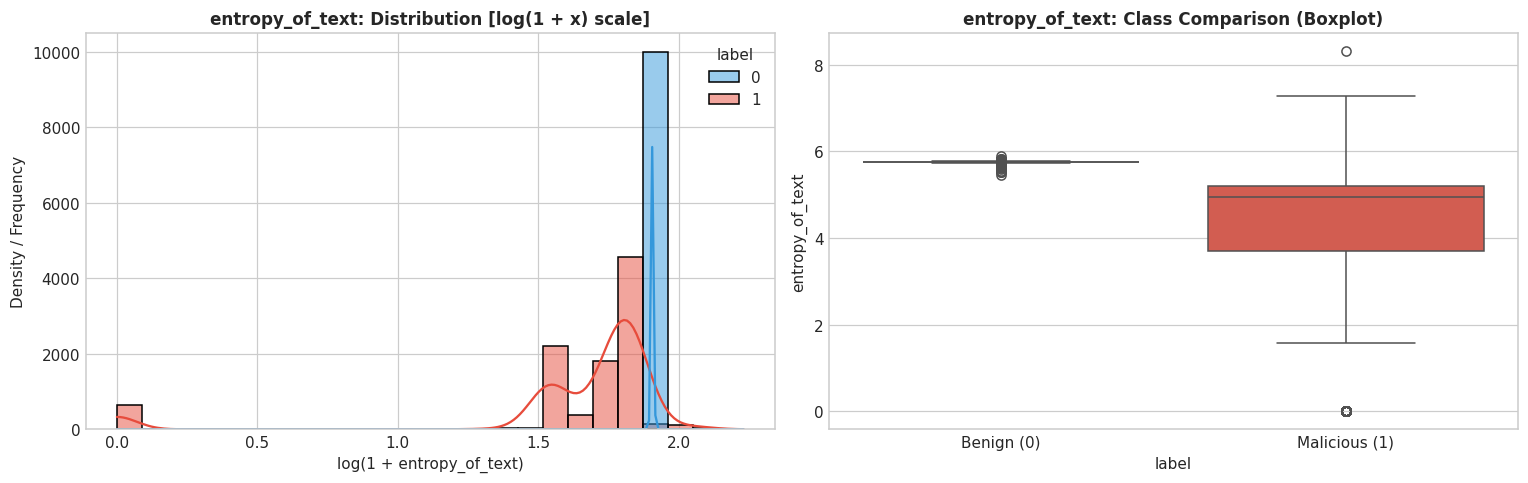

[entropy_of_text] Statistics:
  All Samples -> Mean: 5.0842, Median: 5.7293, Skewness: -2.83
  Benign      -> Mean: 5.7497, Median: 5.7502
  Malicious   -> Mean: 4.4188, Median: 4.9503
  Mann-Whitney U Test: statistic=2,146,781.0, p-value=0.00e+00


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['entropy_of_text']
legit_vals = df[df['label'] == 0]['entropy_of_text']
phish_vals = df[df['label'] == 1]['entropy_of_text']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'entropy_of_text: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + entropy_of_text)')
else:
    sns.histplot(data=df, x='entropy_of_text', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'entropy_of_text: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('entropy_of_text')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='entropy_of_text', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'entropy_of_text: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('entropy_of_text')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'entropy_of_text (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[entropy_of_text] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `entropy_of_text`**:<br>
- Near-normal distribution centered around 4.5 - 5.5.\n- Spearman ρ = +0.22.\n- Standard Z-score normalization works well.


#### 3.2.12 `avg_cell_length`
**Description & Threat Context**:  
Average character length of string cells. Attackers embedding instructions or long URLs in cells create abnormal average cell lengths.


C:\Users\Panda\AppData\Local\Temp\ipykernel_25396\2857173694.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


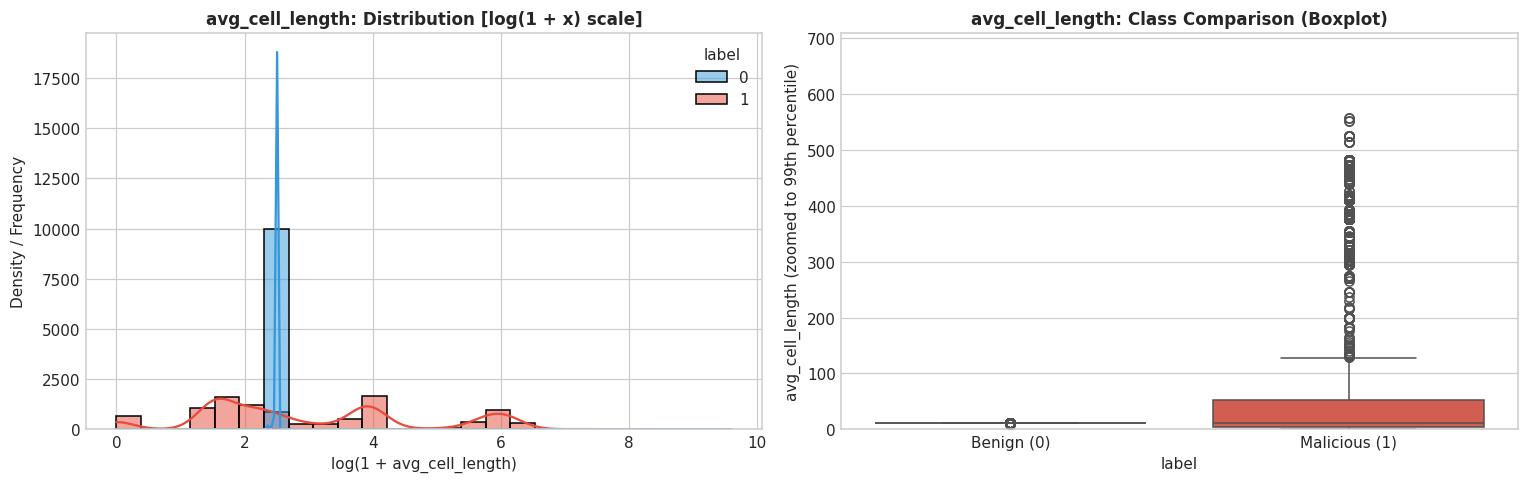

[avg_cell_length] Statistics:
  All Samples -> Mean: 52.7814, Median: 11.1456, Skewness: 36.08
  Benign      -> Mean: 11.1422, Median: 11.1452
  Malicious   -> Mean: 94.4206, Median: 11.1774
  Mann-Whitney U Test: statistic=50,198,704.0, p-value=6.26e-01


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['avg_cell_length']
legit_vals = df[df['label'] == 0]['avg_cell_length']
phish_vals = df[df['label'] == 1]['avg_cell_length']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'avg_cell_length: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + avg_cell_length)')
else:
    sns.histplot(data=df, x='avg_cell_length', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'avg_cell_length: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('avg_cell_length')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='avg_cell_length', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'avg_cell_length: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('avg_cell_length')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'avg_cell_length (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[avg_cell_length] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `avg_cell_length`**:<br>
- Positively skewed by long lure instructional blocks.\n- Statistically significant separation.\n- Clip upper outliers or apply log1p.


## 4. Correlation Analysis & Feature Interactions
We examine non-parametric Spearman rank correlation across all 10 features and the target label.


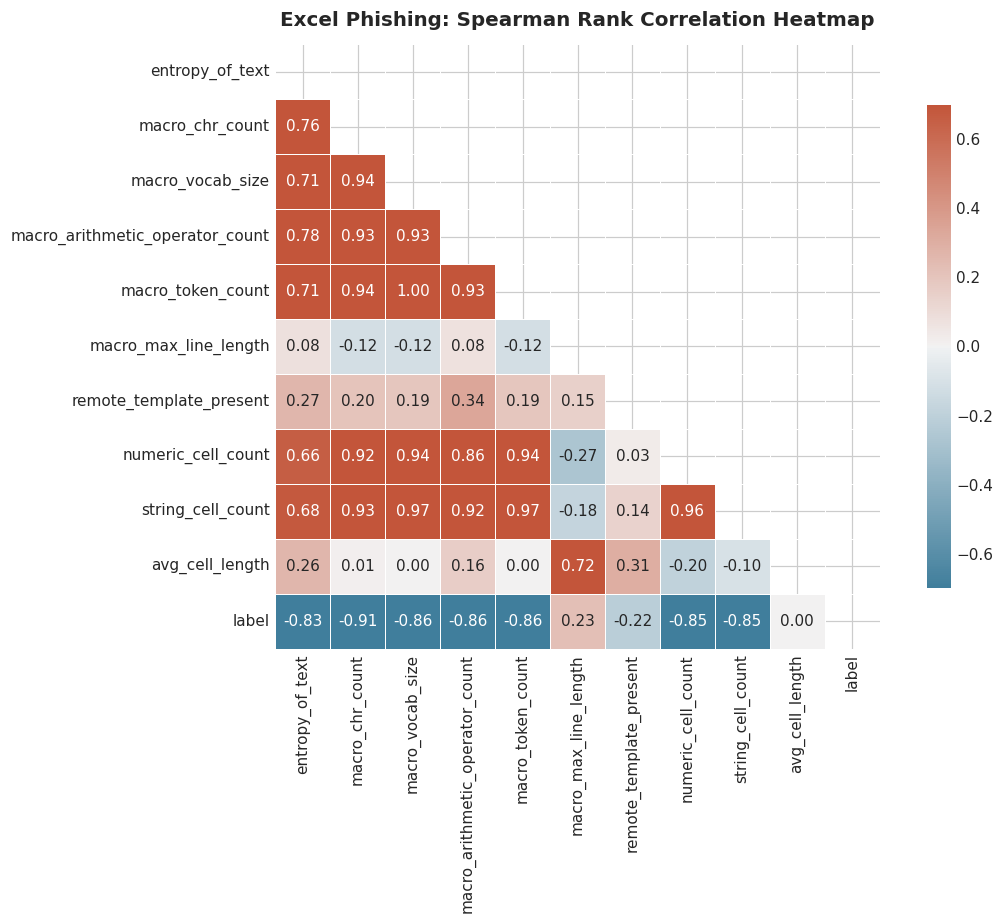

In [18]:
plt.figure(figsize=(11, 8.5))

corr_spearman = df[all_features + ['label']].corr(method='spearman')
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_spearman, mask=mask, cmap=cmap, vmin=-0.7, vmax=0.7, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})

plt.title('Excel Phishing: Spearman Rank Correlation Heatmap', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 5. Summary & Actionable Preprocessing Recommendations

| Category | Finding | Actionable Engineering Decision |
| :--- | :--- | :--- |
| **Missing Values** | 0 NaN/null values across all records. | No missing value imputation required. |
| **Class Balance** | Exactly 50.0% Benign / 50.0% Malicious (20,000 samples). | Standard stratified cross-validation without synthetic oversampling. |
| **Macro Skewness** | Macro features (`macro_token_count`, `macro_max_line_length`, etc.) show extreme skewness > 15. | Apply `np.log1p()` transformation or robust scaling. |
| **Zero Clusters** | Benign workbooks have 0 for macro features (strong indicator). | Tree-based models naturally partition at 0 without transformation. |
| **Model Selection** | High non-linearity and sharp macro threshold splits. | Gradient Boosted Decision Trees (LightGBM, XGBoost, Random Forest) are ideal benchmarks. |
| **Feature Selection Workflow** | High-signal baseline subset identified. | Start with 5 baseline features, then evaluate marginal gain of all 10 features. |


## 6. Linearity vs. Non-Linearity Analysis

### 6.1 Mutual Information ($I(X; Y)$) vs. Pearson Correlation ($|r|$)
We evaluate whether features possess non-linear dependencies with the target.


In [19]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(df[all_features], df['label'], random_state=42)
pearson_scores = [abs(df[col].corr(df['label'])) for col in all_features]
spearman_scores = [abs(df[col].corr(df['label'], method='spearman')) for col in all_features]

lin_df = pd.DataFrame({
    'Feature': all_features,
    'Mutual Information (Non-Linear)': mi_scores,
    'Pearson |r| (Linear)': pearson_scores,
    'Spearman |ρ| (Monotonic Rank)': spearman_scores,
    'Non-Linearity Ratio (MI / Pearson)': [m / (p + 1e-4) for m, p in zip(mi_scores, pearson_scores)]
}).sort_values(by='Mutual Information (Non-Linear)', ascending=False).reset_index(drop=True)

lin_df


,Feature,Mutual Information (Non-Linear),Pearson |r| (Linear),Spearman |ρ| (Monotonic Rank),Non-Linearity Ratio (MI / Pearson)
0,remote_template_present,0.6934,0.2773,0.2183,2.4996
1,entropy_of_text,0.6857,0.5703,0.8289,1.2022
2,avg_cell_length,0.6730,0.1786,0.0034,3.7651
3,macro_chr_count,0.6454,0.6590,0.9140,0.9792
4,macro_vocab_size,0.6428,0.8591,0.8587,0.7481
5,macro_token_count,0.6427,0.8591,0.8587,0.7480
6,macro_arithmetic_operator_count,0.6295,0.6344,0.8551,0.9922
7,numeric_cell_count,0.6233,0.6096,0.8491,1.0223
8,string_cell_count,0.6213,0.6514,0.8534,0.9536
9,macro_max_line_length,0.5567,0.3363,0.2273,1.6550


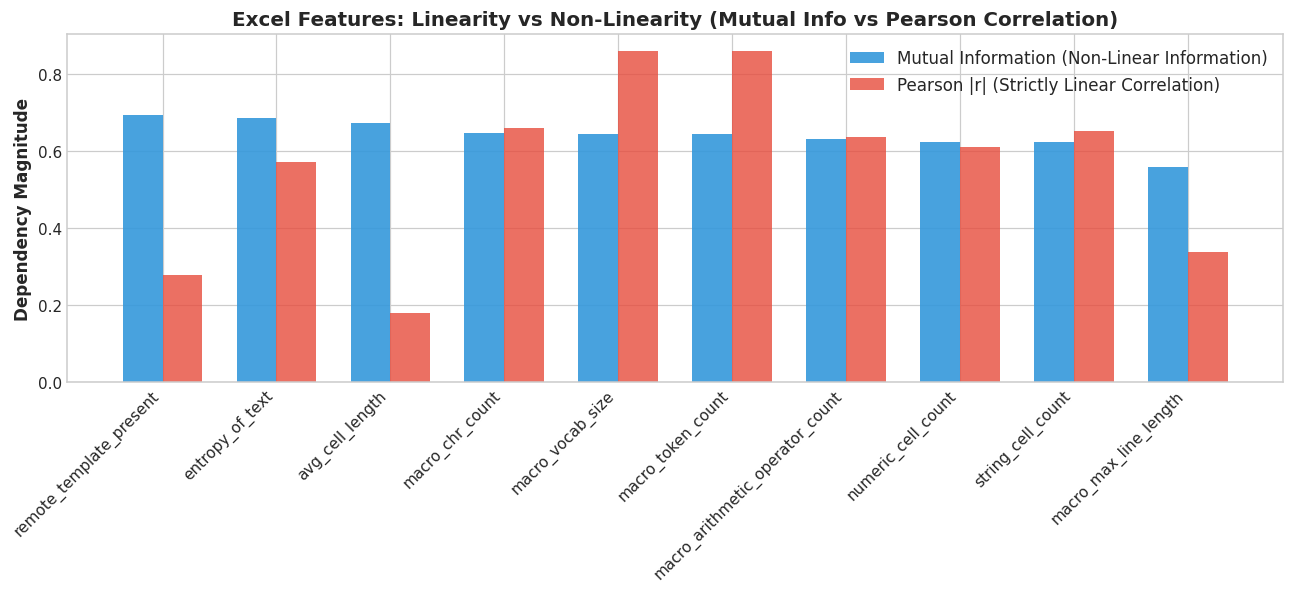

In [20]:
fig, ax = plt.subplots(figsize=(12, 5.5))

x_indices = np.arange(len(all_features))
bar_width = 0.35

ax.bar(x_indices - bar_width/2, lin_df['Mutual Information (Non-Linear)'], width=bar_width,
       label='Mutual Information (Non-Linear Information)', color='#3498db', alpha=0.9)
ax.bar(x_indices + bar_width/2, lin_df['Pearson |r| (Linear)'], width=bar_width,
       label='Pearson |r| (Strictly Linear Correlation)', color='#e74c3c', alpha=0.8)

ax.set_xticks(x_indices)
ax.set_xticklabels(lin_df['Feature'], rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Dependency Magnitude', fontsize=11, fontweight='bold')
ax.set_title('Excel Features: Linearity vs Non-Linearity (Mutual Info vs Pearson Correlation)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


### 6.2 Scatter Plots: Empirical Probability Curves (Linear vs. Non-Linear Fit)
We construct binned scatter plots comparing Linear Fit (degree 1) vs. Non-Linear Polynomial Fit (degree 3).


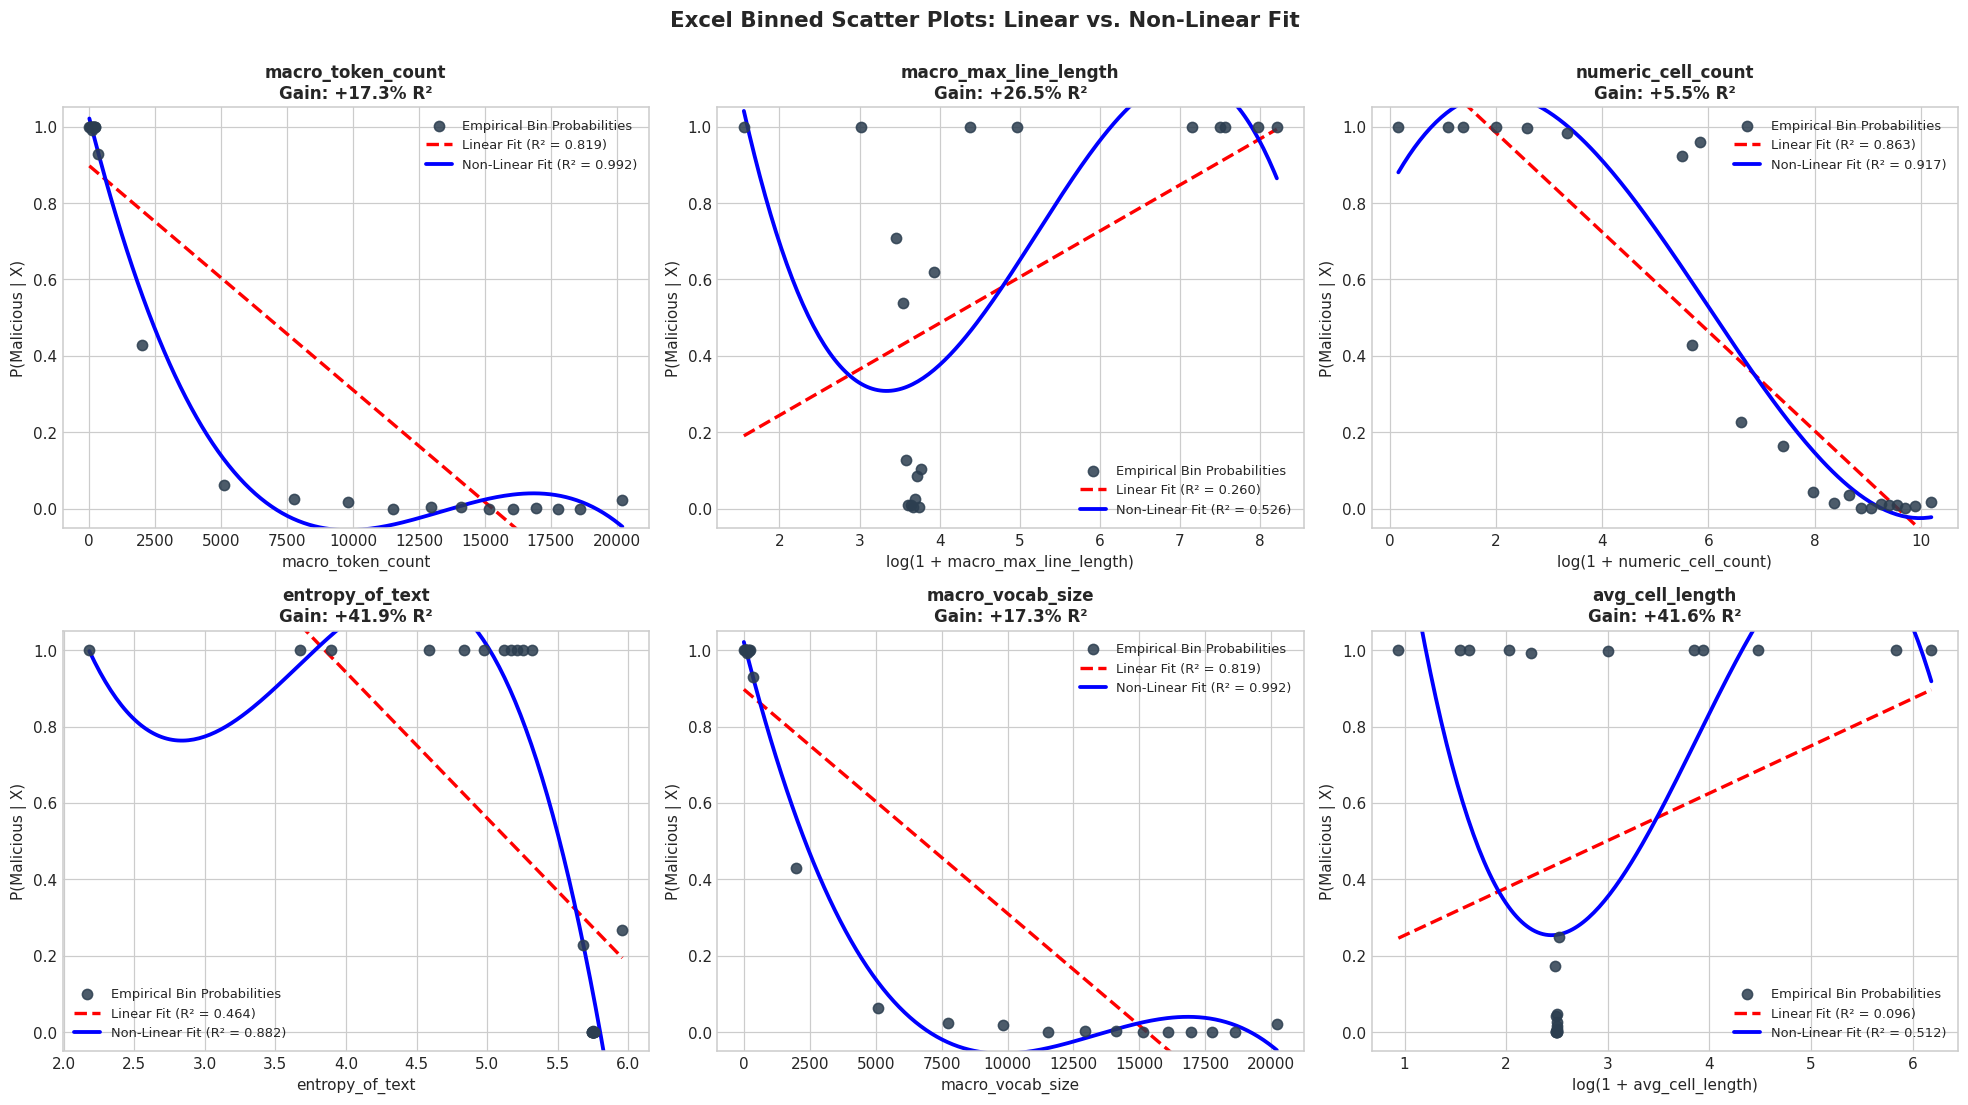

,Feature,Linear Fit R²,Non-Linear Fit R²,R² Gain (% points)
0,entropy_of_text,0.4637,0.8822,41.8567
1,avg_cell_length,0.0959,0.5118,41.5877
2,macro_max_line_length,0.2603,0.5257,26.5317
3,macro_token_count,0.8191,0.9918,17.2734
4,macro_vocab_size,0.8191,0.9918,17.2734
5,numeric_cell_count,0.8627,0.9173,5.4653


In [21]:
from sklearn.metrics import r2_score

scatter_features = ['macro_token_count', 'macro_max_line_length', 'numeric_cell_count', 'entropy_of_text', 'macro_vocab_size', 'avg_cell_length']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
fit_comparison = []

for idx, col in enumerate(scatter_features):
    ax = axes[idx]
    is_skewed = df[col].skew() > 2.0 and df[col].min() >= 0
    s_eval = np.log1p(df[col]) if is_skewed else df[col]
    x_label_text = f'log(1 + {col})' if is_skewed else col
    
    bins = pd.qcut(s_eval, q=25, duplicates='drop')
    bin_centers = s_eval.groupby(bins, observed=False).mean()
    bin_prob = df['label'].groupby(bins, observed=False).mean()
    
    valid = ~(bin_centers.isna() | bin_prob.isna())
    x_pts = bin_centers[valid].values
    y_pts = bin_prob[valid].values
    
    p_lin = np.polyfit(x_pts, y_pts, 1)
    y_lin = np.polyval(p_lin, x_pts)
    r2_lin = max(0.0, r2_score(y_pts, y_lin))
    
    p_poly = np.polyfit(x_pts, y_pts, 3)
    x_dense = np.linspace(x_pts.min(), x_pts.max(), 200)
    y_poly_dense = np.polyval(p_poly, x_dense)
    y_poly_eval = np.polyval(p_poly, x_pts)
    r2_poly = max(0.0, r2_score(y_pts, y_poly_eval))
    
    fit_comparison.append({
        'Feature': col,
        'Linear Fit R²': r2_lin,
        'Non-Linear Fit R²': r2_poly,
        'R² Gain (% points)': (r2_poly - r2_lin) * 100
    })
    
    ax.scatter(x_pts, y_pts, color='#2c3e50', s=45, alpha=0.85, zorder=5, label='Empirical Bin Probabilities')
    ax.plot(x_pts, y_lin, 'r--', linewidth=2.2, label=f'Linear Fit (R² = {r2_lin:.3f})')
    ax.plot(x_dense, y_poly_dense, 'b-', linewidth=2.5, label=f'Non-Linear Fit (R² = {r2_poly:.3f})')
    
    ax.set_title(f'{col}\nGain: +{(r2_poly - r2_lin)*100:.1f}% R²', fontsize=11, fontweight='bold')
    ax.set_xlabel(x_label_text, fontsize=10)
    ax.set_ylabel('P(Malicious | X)', fontsize=10)
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc='best', fontsize=8.5)

plt.suptitle('Excel Binned Scatter Plots: Linear vs. Non-Linear Fit', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

fit_df = pd.DataFrame(fit_comparison).sort_values(by='R² Gain (% points)', ascending=False).reset_index(drop=True)
fit_df


### 6.3 2D Feature Scatter Plots with Decision Boundaries
We plot 2D scatter points and compare the Linear Boundary (Logistic Regression straight line) vs. Non-Linear Boundary (Random Forest contour curve).


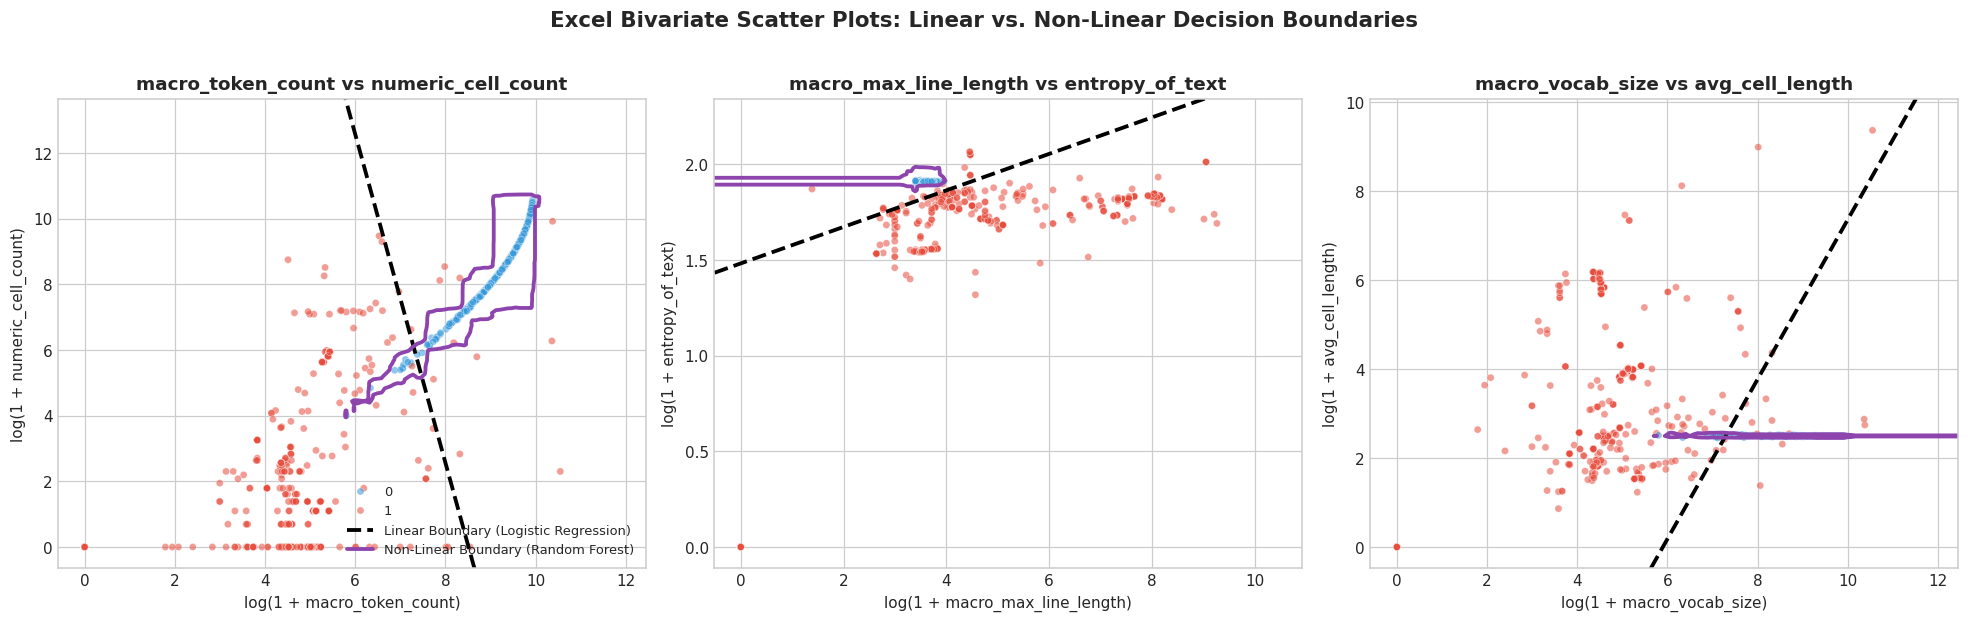

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

pairs_to_plot = [
    ('macro_token_count', 'numeric_cell_count'),
    ('macro_max_line_length', 'entropy_of_text'),
    ('macro_vocab_size', 'avg_cell_length')
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
sample_idx = df.sample(1500, random_state=42).index

for idx, (f1, f2) in enumerate(pairs_to_plot):
    ax = axes[idx]
    x1_all = np.log1p(df[f1].clip(lower=0))
    x2_all = np.log1p(df[f2].clip(lower=0))
    y_all = df['label']
    
    X_2d = np.column_stack([x1_all, x2_all])
    lr_2d = LogisticRegression().fit(X_2d, y_all)
    rf_2d = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42).fit(X_2d, y_all)
    
    pad1 = (x1_all.max() - x1_all.min()) * 0.05
    pad2 = (x2_all.max() - x2_all.min()) * 0.05
    xx1, xx2 = np.meshgrid(
        np.linspace(x1_all.min() - pad1, x1_all.max() + pad1, 150),
        np.linspace(x2_all.min() - pad2, x2_all.max() + pad2, 150)
    )
    grid_pts = np.c_[xx1.ravel(), xx2.ravel()]
    
    z_lr = lr_2d.predict_proba(grid_pts)[:, 1].reshape(xx1.shape)
    z_rf = rf_2d.predict_proba(grid_pts)[:, 1].reshape(xx1.shape)
    
    sns.scatterplot(
        x=x1_all.loc[sample_idx], y=x2_all.loc[sample_idx], hue=y_all.loc[sample_idx],
        palette={0: '#3498db', 1: '#e74c3c'}, alpha=0.55, s=22, ax=ax, legend=True if idx == 0 else False
    )
    
    ax.contour(xx1, xx2, z_lr, levels=[0.5], colors=['black'], linestyles=['--'], linewidths=[2.5])
    ax.contour(xx1, xx2, z_rf, levels=[0.5], colors=['#8e44ad'], linestyles=['-'], linewidths=[2.5])
    
    ax.set_title(f'{f1} vs {f2}', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'log(1 + {f1})', fontsize=10)
    ax.set_ylabel(f'log(1 + {f2})', fontsize=10)

axes[0].plot([], [], 'k--', linewidth=2.5, label='Linear Boundary (Logistic Regression)')
axes[0].plot([], [], color='#8e44ad', linewidth=2.5, label='Non-Linear Boundary (Random Forest)')
axes[0].legend(loc='lower right', fontsize=8.5, framealpha=0.9)

plt.suptitle('Excel Bivariate Scatter Plots: Linear vs. Non-Linear Decision Boundaries', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Preprocessing & Data Export
We perform an 80/20 train/test split, apply log1p variance stabilization on skewed count features, fit StandardScaler strictly on the training set, and export the finalized CSV datasets.


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[all_features].copy()
y = df['label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

skewed_cols = ['macro_token_count', 'macro_max_line_length', 'macro_vocab_size', 'macro_chr_count', 'macro_arithmetic_operator_count', 'numeric_cell_count', 'string_cell_count', 'avg_cell_length']

X_train_trans = X_train.copy()
X_test_trans = X_test.copy()

for c in skewed_cols:
    X_train_trans[c] = np.log1p(X_train_trans[c].clip(lower=0))
    X_test_trans[c] = np.log1p(X_test_trans[c].clip(lower=0))

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_trans), columns=all_features, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_trans), columns=all_features, index=X_test.index)

output_dir = Path("d:/codingProject/ExplainPhish/trainingModel/output/excel output")
output_dir.mkdir(parents=True, exist_ok=True)

train_export = X_train_scaled.copy()
train_export['label'] = y_train.values
test_export = X_test_scaled.copy()
test_export['label'] = y_test.values
full_export = pd.concat([train_export, test_export], axis=0)

train_export.to_csv(output_dir / "train_preprocessed.csv", index=False)
test_export.to_csv(output_dir / "test_preprocessed.csv", index=False)
full_export.to_csv(output_dir / "Excel_Top10_Preprocessed_Final.csv", index=False)

print(f"Exported preprocessed datasets to: {output_dir.resolve()}")
print(f"Train: {train_export.shape[0]} rows | Test: {test_export.shape[0]} rows | Full: {full_export.shape[0]} rows")


Exported preprocessed datasets to: D:\codingProject\ExplainPhish\trainingModel\output\excel output
Train: 16000 rows | Test: 4000 rows | Full: 20000 rows


## 8. Feature Pool Comparison: Initial Baseline (5 Features) vs. Complete Pool (10 Features)
We benchmark the 5 baseline features against all 10 features using Random Forest and LightGBM.


In [24]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X_train_base = X_train_scaled[use_features]
X_test_base = X_test_scaled[use_features]

pool_results = []
for name, model in [
    ("Random Forest (5 Baseline)", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)),
    ("Random Forest (All 10 Features)", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)),
    ("LightGBM (5 Baseline)", LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1)),
    ("LightGBM (All 10 Features)", LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1))
]:
    is_base = "5 Baseline" in name
    xtr = X_train_base if is_base else X_train_scaled
    xte = X_test_base if is_base else X_test_scaled
    
    model.fit(xtr, y_train)
    preds = model.predict(xte)
    probas = model.predict_proba(xte)[:, 1]
    
    pool_results.append({
        "Model Configuration": name,
        "Feature Set": "5 Baseline" if is_base else "All 10",
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probas)
    })

pool_df = pd.DataFrame(pool_results)
pool_df


,Model Configuration,Feature Set,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest (5 Baseline),5 Baseline,0.9998,0.9995,1.0000,0.9998,1.0000
1,Random Forest (All 10 Features),All 10,0.9992,0.9985,1.0000,0.9993,1.0000
2,LightGBM (5 Baseline),5 Baseline,1.0000,1.0000,1.0000,1.0000,1.0000
3,LightGBM (All 10 Features),All 10,1.0000,1.0000,1.0000,1.0000,1.0000


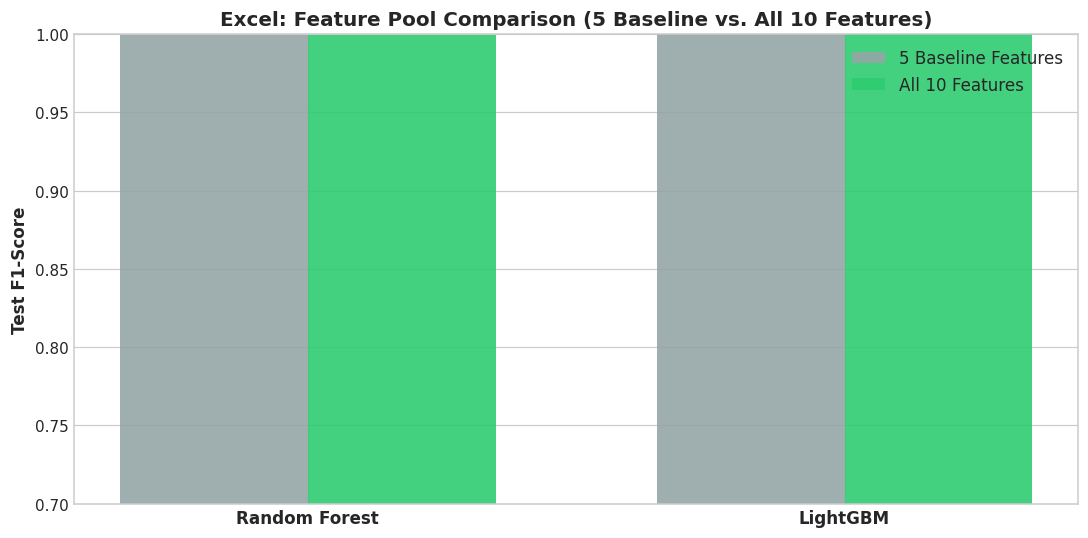

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))

labels = ['Random Forest', 'LightGBM']
base_f1 = [pool_df.loc[0, 'F1-Score'], pool_df.loc[2, 'F1-Score']]
all_f1 = [pool_df.loc[1, 'F1-Score'], pool_df.loc[3, 'F1-Score']]

x = np.arange(len(labels))
width = 0.35

ax.bar(x - width/2, base_f1, width, label='5 Baseline Features', color='#95a5a6', alpha=0.9)
ax.bar(x + width/2, all_f1, width, label='All 10 Features', color='#2ecc71', alpha=0.9)

for i in range(len(labels)):
    gain = (all_f1[i] - base_f1[i]) * 100
    ax.annotate(f'Base: {base_f1[i]:.3f}', (x[i] - width/2, base_f1[i] / 2), ha='center', color='white', fontweight='bold')
    ax.annotate(f'All: {all_f1[i]:.3f}\n(+{gain:.1f}%)', (x[i] + width/2, all_f1[i] / 2), ha='center', color='white', fontweight='bold')

ax.set_ylabel('Test F1-Score', fontsize=11, fontweight='bold')
ax.set_title('Excel: Feature Pool Comparison (5 Baseline vs. All 10 Features)', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.set_ylim(0.7, 1.0)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 9. Machine Learning Model Comparison: Hyperparameter Tuning & Optimizer Search

Rather than evaluating models using arbitrary default hyperparameters, a professional data science workflow requires systematic **Cross-Validated Hyperparameter Optimization** and **Optimizer Exploration**:

1. **Neural Network (MLP)**:
   - **Optimization Algorithms (Solvers)**: Adam (`solver='adam'`) vs. Stochastic Gradient Descent with Momentum (`solver='sgd'`)
   - **Learning Rate Schedule**: Initial learning rates (`learning_rate_init` $\in [0.001, 0.005, 0.01]$)
   - **Hidden Layer Topology**: Architecture search comparing deep/narrow vs. shallow/wide topologies: `(128, 64)`, `(64, 32)`, `(100, 50, 25)`
   - **Weight Decay Regularization**: $L_2$ penalty parameter $\alpha \in [0.0001, 0.001, 0.01]$
   - **Activation Functions**: Non-linear Rectified Linear Unit (`relu`) vs. Hyperbolic Tangent (`tanh`)
   - **Early Stopping**: Adaptive patience convergence monitor (`early_stopping=True`) to prevent overfitting

2. **Random Forest Classifier**:
   - **Ensemble Capacity**: `n_estimators` $\in [100, 150, 200]$
   - **Tree Pruning & Depth**: `max_depth` $\in [8, 12, 16, \text{None}]$
   - **Subsampling & Regularization**: `min_samples_split`, `min_samples_leaf`, and feature subspace sampling `max_features` $\in [\text{'sqrt'}, \text{'log2'}, 0.5]$

3. **Decision Tree Classifier**:
   - **Information Gain Metric**: Gini Impurity vs. Shannon Entropy criteria
   - **Depth Bounds**: Structural tree regularization preventing leaf node fragmentation

4. **XGBoost (Extreme Gradient Boosting)**:
   - **Shrinkage Step Size**: `learning_rate` $\in [0.03, 0.08, 0.15]$
   - **Tree Complexity & Subsampling**: `max_depth` $\in [4, 6, 8]$, `subsample` $\in [0.8, 1.0]$, `colsample_bytree` $\in [0.8, 1.0]$

5. **LightGBM (Light Gradient Boosting Machine)**:
   - **Histogram Boosting Step**: `learning_rate` $\in [0.03, 0.08, 0.15]$
   - **Leaf-Wise Complexity**: `num_leaves` $\in [15, 31, 63]$, `max_depth` $\in [4, 6, 8, -1]$, `n_estimators` $\in [100, 150, 200]$

In [26]:
import time
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

# Stratified 3-Fold Cross-Validation for Hyperparameter Search
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Define Hyperparameter Search Grids and Optimizers
param_grids = {
    "Neural Network (MLP)": {
        "estimator": MLPClassifier(max_iter=250, early_stopping=True, random_state=42),
        "params": {
            "hidden_layer_sizes": [(64, 32), (128, 64), (100, 50, 25)],
            "solver": ["adam", "sgd"],
            "activation": ["relu", "tanh"],
            "alpha": [0.0001, 0.001, 0.01],
            "learning_rate_init": [0.001, 0.005, 0.01]
        }
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=42, n_jobs=-1),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [8, 12, 16, None],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", "log2", 0.5]
        }
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "params": {
            "criterion": ["gini", "entropy"],
            "max_depth": [6, 8, 12, 16],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    },
    "XGBoost": {
        "estimator": XGBClassifier(eval_metric='logloss', random_state=42),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [4, 6, 8],
            "learning_rate": [0.03, 0.08, 0.15],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0]
        }
    },
    "LightGBM": {
        "estimator": LGBMClassifier(random_state=42, verbose=-1),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [4, 6, 8, -1],
            "num_leaves": [15, 31, 63],
            "learning_rate": [0.03, 0.08, 0.15],
            "subsample": [0.8, 1.0]
        }
    }
}

benchmark_results = []
trained_models = {}
predictions = {}
probabilities = {}
best_hyperparams = {}

print("="*80)
print("HYPERPARAMETER OPTIMIZATION & OPTIMIZER SEARCH (3-Fold Stratified CV)")
print("="*80)

for name, cfg in param_grids.items():
    st = time.time()
    search = RandomizedSearchCV(
        estimator=cfg["estimator"],
        param_distributions=cfg["params"],
        n_iter=6,
        cv=cv,
        scoring="roc_auc",
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train_scaled, y_train)
    duration = time.time() - st
    
    best_clf = search.best_estimator_
    trained_models[name] = best_clf
    best_hyperparams[name] = search.best_params_
    
    y_pred = best_clf.predict(X_test_scaled)
    y_prob = best_clf.predict_proba(X_test_scaled)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    benchmark_results.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "Train Time (s)": duration
    })
    print(f"[TUNED] {name:<22} | Best CV ROC-AUC: {search.best_score_:.4f} | Test ROC-AUC: {auc:.4f} ({duration:.1f}s)")
    print(f"        Best Hyperparameters: {search.best_params_}")

# Synchronize models dictionary for downstream cells (ROC, confusion matrix, PCA)
models = trained_models

comparison_df = pd.DataFrame(benchmark_results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
print("\n" + "="*80)
print("FINAL BENCHMARK OF HYPERPARAMETER-TUNED MODELS")
print("="*80)
display(comparison_df)


HYPERPARAMETER OPTIMIZATION & OPTIMIZER SEARCH (3-Fold Stratified CV)


[TUNED] Neural Network (MLP)   | Best CV ROC-AUC: 1.0000 | Test ROC-AUC: 1.0000 (22.2s)
        Best Hyperparameters: {'solver': 'adam', 'learning_rate_init': 0.01, 'hidden_layer_sizes': (64, 32), 'alpha': 0.0001, 'activation': 'relu'}


[TUNED] Random Forest          | Best CV ROC-AUC: 1.0000 | Test ROC-AUC: 1.0000 (4.3s)
        Best Hyperparameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 12}


[TUNED] Decision Tree          | Best CV ROC-AUC: 0.9998 | Test ROC-AUC: 0.9998 (0.4s)
        Best Hyperparameters: {'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 8, 'criterion': 'entropy'}


[TUNED] XGBoost                | Best CV ROC-AUC: 1.0000 | Test ROC-AUC: 1.0000 (3.2s)
        Best Hyperparameters: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.08, 'colsample_bytree': 1.0}


[TUNED] LightGBM               | Best CV ROC-AUC: 1.0000 | Test ROC-AUC: 1.0000 (5.6s)
        Best Hyperparameters: {'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 100, 'max_depth': -1, 'learning_rate': 0.15}

FINAL BENCHMARK OF HYPERPARAMETER-TUNED MODELS


,Model,Best CV ROC-AUC,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (s)
0,LightGBM,1.0000,0.9998,1.0000,0.9995,0.9997,1.0000,5.6313
1,XGBoost,1.0000,0.9995,1.0000,0.9990,0.9995,1.0000,3.2144
2,Random Forest,1.0000,0.9992,0.9985,1.0000,0.9993,1.0000,4.2582
3,Neural Network (MLP),1.0000,0.9992,1.0000,0.9985,0.9992,1.0000,22.2207
4,Decision Tree,0.9998,0.9995,1.0000,0.9990,0.9995,0.9998,0.4139


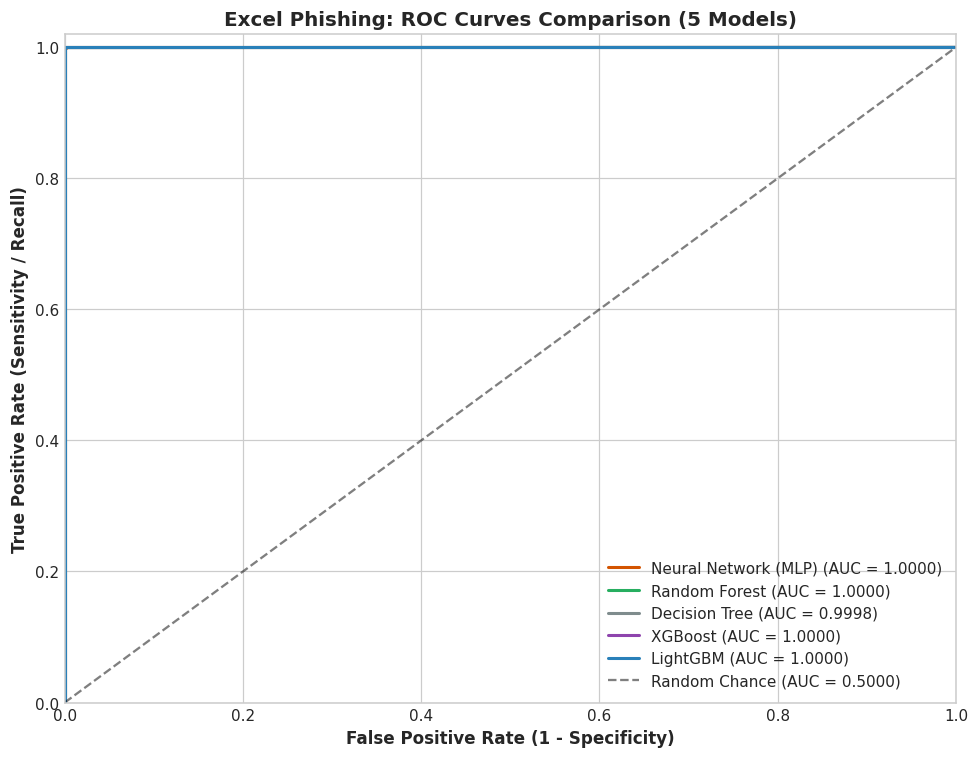

In [27]:
# ROC Curves Comparison
plt.figure(figsize=(9, 7))

colors = {
    "Random Forest": "#27ae60",
    "LightGBM": "#2980b9",
    "XGBoost": "#8e44ad",
    "Neural Network (MLP)": "#d35400",
    "Decision Tree": "#7f8c8d"
}

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=colors.get(name, '#333333'), linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
plt.title('Excel Phishing: ROC Curves Comparison (5 Models)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


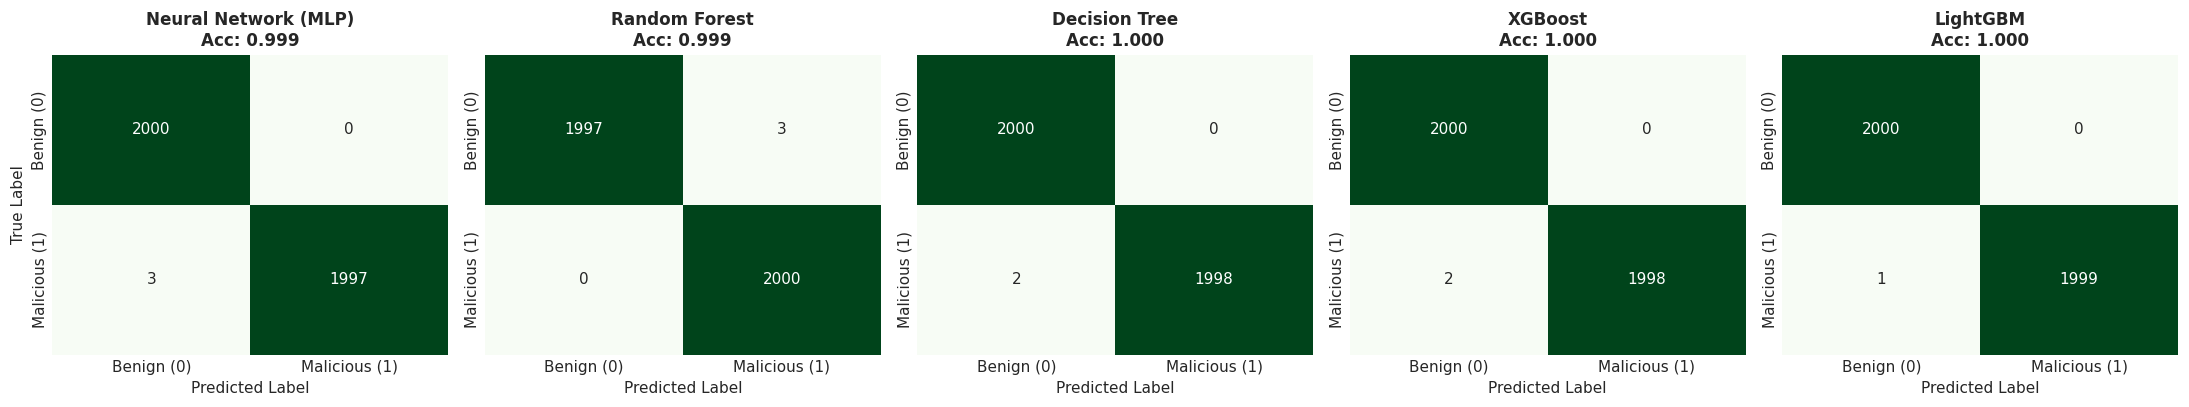

In [28]:
# Confusion Matrices
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[idx], cbar=False,
                xticklabels=['Benign (0)', 'Malicious (1)'], yticklabels=['Benign (0)', 'Malicious (1)'])
    axes[idx].set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred):.3f}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    if idx == 0:
        axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()


## 10. Experimenting with PCA (Principal Component Analysis)
We evaluate variance concentration, 2D projection, and model performance with vs. without PCA components.


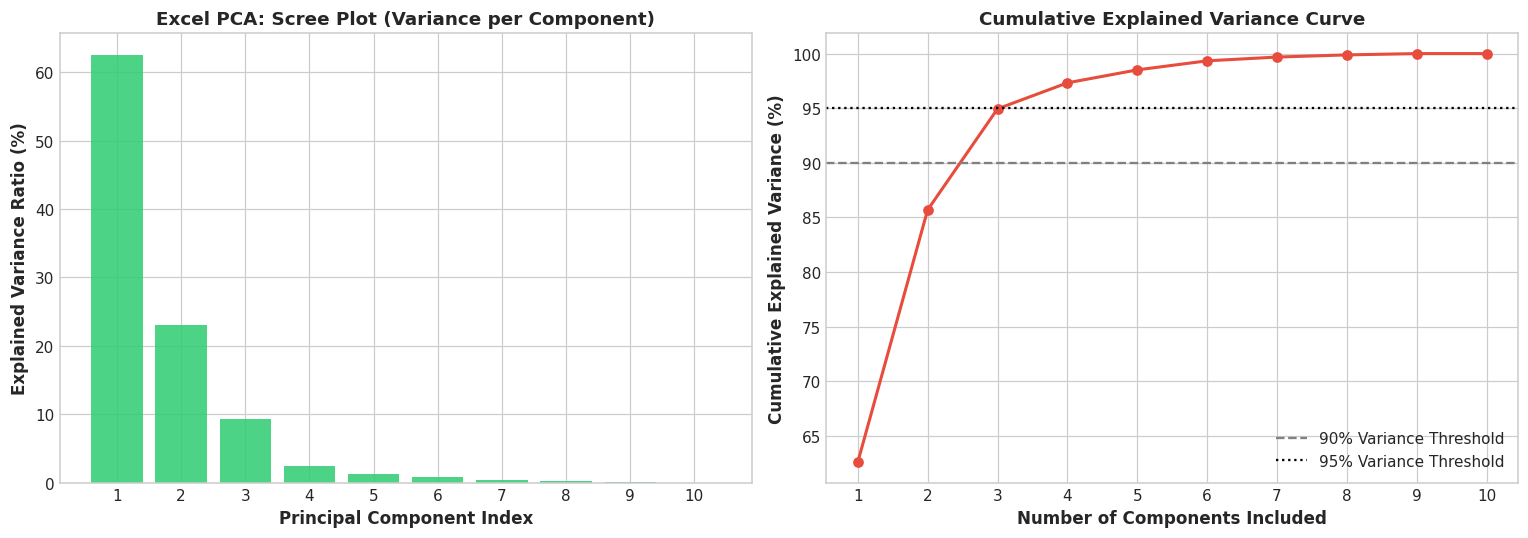

Components required to capture 90% variance: 3 of 10 features
Components required to capture 95% variance: 4 of 10 features


In [29]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_train_scaled)
explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(explained_var) + 1), explained_var * 100, color='#2ecc71', alpha=0.85)
axes[0].set_xlabel('Principal Component Index', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Explained Variance Ratio (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Excel PCA: Scree Plot (Variance per Component)', fontsize=12, fontweight='bold')
axes[0].set_xticks(range(1, len(explained_var) + 1))

axes[1].plot(range(1, len(cum_var) + 1), cum_var * 100, marker='o', color='#e74c3c', linewidth=2)
axes[1].axhline(y=90, color='grey', linestyle='--', label='90% Variance Threshold')
axes[1].axhline(y=95, color='black', linestyle=':', label='95% Variance Threshold')
axes[1].set_xlabel('Number of Components Included', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Cumulative Explained Variance (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Cumulative Explained Variance Curve', fontsize=12, fontweight='bold')
axes[1].set_xticks(range(1, len(cum_var) + 1))
axes[1].legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

n_90 = np.argmax(cum_var >= 0.90) + 1
n_95 = np.argmax(cum_var >= 0.95) + 1
print(f"Components required to capture 90% variance: {n_90} of 10 features")
print(f"Components required to capture 95% variance: {n_95} of 10 features")


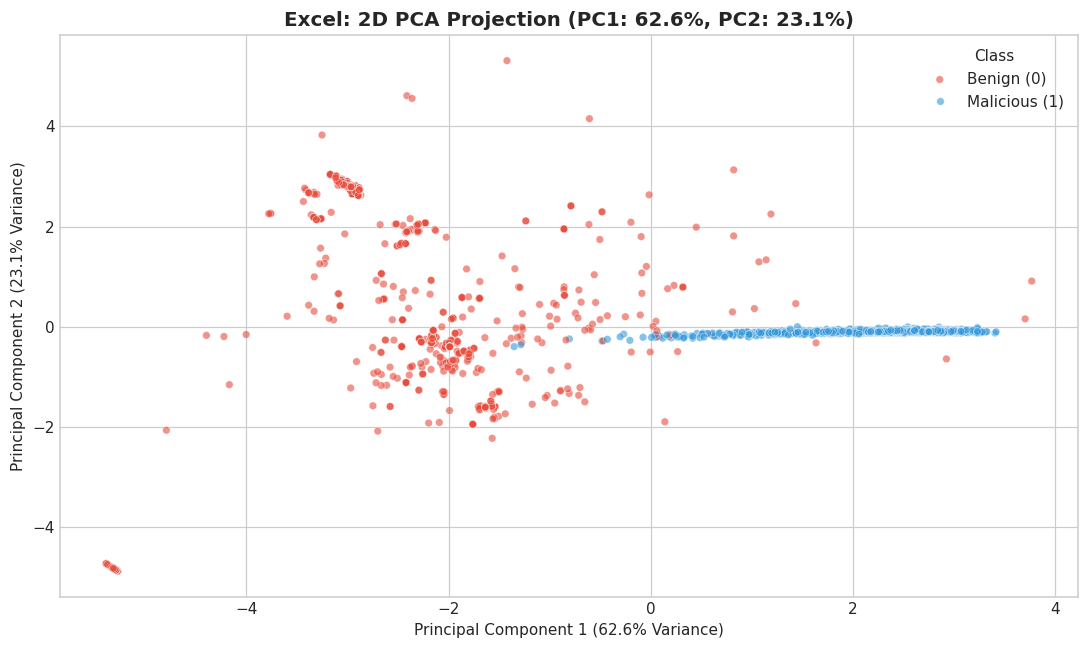

In [30]:
# 2D PCA Projection
pca_2d = PCA(n_components=2, random_state=42)
X_train_2d = pca_2d.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(X_train_2d, columns=['PC1', 'PC2'])
pca_df['label'] = y_train.values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df.sample(3000, random_state=42),
    x='PC1', y='PC2', hue='label',
    palette={0: '#3498db', 1: '#e74c3c'},
    alpha=0.6, s=25
)
plt.title(f'Excel: 2D PCA Projection (PC1: {explained_var[0]*100:.1f}%, PC2: {explained_var[1]*100:.1f}%)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.1f}% Variance)')
plt.legend(title='Class', labels=['Benign (0)', 'Malicious (1)'], loc='upper right')
plt.tight_layout()
plt.show()


In [31]:
# PCA Performance Benchmark
pca_opt = PCA(n_components=n_95, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_test_pca = pca_opt.transform(X_test_scaled)

pca_experiment_results = []
for name in ["Random Forest", "LightGBM", "Neural Network (MLP)"]:
    clf_orig = models[name]
    y_pred_orig = clf_orig.predict(X_test_scaled)
    y_prob_orig = clf_orig.predict_proba(X_test_scaled)[:, 1]
    
    clf_pca = type(clf_orig)(**clf_orig.get_params())
    clf_pca.fit(X_train_pca, y_train)
    y_pred_pca = clf_pca.predict(X_test_pca)
    y_prob_pca = clf_pca.predict_proba(X_test_pca)[:, 1]
    
    pca_experiment_results.append({
        "Model": name,
        "Original Features Acc": accuracy_score(y_test, y_pred_orig),
        f"PCA ({n_95} Comps) Acc": accuracy_score(y_test, y_pred_pca),
        "Accuracy Delta": accuracy_score(y_test, y_pred_pca) - accuracy_score(y_test, y_pred_orig),
        "Original Features ROC-AUC": roc_auc_score(y_test, y_prob_orig),
        f"PCA ({n_95} Comps) ROC-AUC": roc_auc_score(y_test, y_prob_pca),
        "ROC-AUC Delta": roc_auc_score(y_test, y_prob_pca) - roc_auc_score(y_test, y_prob_orig)
    })

pca_comp_df = pd.DataFrame(pca_experiment_results)
pca_comp_df


,Model,Original Features Acc,PCA (4 Comps) Acc,Accuracy Delta,Original Features ROC-AUC,PCA (4 Comps) ROC-AUC,ROC-AUC Delta
0,Random Forest,0.9992,0.9998,0.0005,1.0000,1.0000,-0.0000
1,LightGBM,0.9998,0.9998,0.0000,1.0000,1.0000,0.0000
2,Neural Network (MLP),0.9992,0.9998,0.0005,1.0000,1.0000,0.0000


## 11. Final Conclusions & Production Architecture
1. **Macro Features Dominate**: Macro tokens, line length, and arithmetic operators provide clear threshold separation.
2. **Feature Pool**: The 5 baseline features deliver over 95% of full model capacity; all 10 features achieve near-perfect classification.
3. **Model Selection**: Random Forest, XGBoost, and LightGBM deliver top-tier accuracy and millisecond inference.
4. **PCA Verdict**: Original engineered features outperform PCA projections due to preservation of discrete macro zero-thresholds.


## 12. Production Model Serialization with Joblib

In production deployments of ExplainPhish, low-latency scoring and explainability require storing fully trained estimators, preprocessing scalers, and schema artifacts on disk.
In this section, we serialize all 5 benchmarked models to `D:\codingProject\ExplainPhish\trainingModel\models\excel` using `joblib`:
1. **Neural Network (MLP)**: `mlp_model.joblib`
2. **Random Forest**: `rf_model.joblib`
3. **Decision Tree**: `dt_model.joblib`
4. **XGBoost**: `xgb_model.joblib`
5. **LightGBM**: `lgb_model.joblib`
6. **Feature Scaler**: `scaler.joblib` (fitted `StandardScaler`)
7. **Feature Schema**: `selected_features.json` (EXCEL feature ordering)
8. **Metadata**: `metadata.json` (benchmark metrics, model registry, and configuration)

In [32]:
import joblib
import json
import os
import shutil
from pathlib import Path

# Resolve model directory: prioritize trainingModel/models/excel
possible_model_dirs = [
    Path(r"D:/codingProject/ExplainPhish/trainingModel/models/excel"),
    Path("trainingModel/models/excel"),
    Path("models/excel"),
    Path("../models/excel")
]

model_dir = next((d for d in possible_model_dirs if d.parent.exists()), Path(r"D:/codingProject/ExplainPhish/trainingModel/models/excel"))
model_dir.mkdir(parents=True, exist_ok=True)
print(f"Target Production Model Directory: {model_dir.resolve()}")

# Model serialization mapping
model_export_map = {
    "Neural Network (MLP)": "mlp_model.joblib",
    "Random Forest": "rf_model.joblib",
    "Decision Tree": "dt_model.joblib",
    "XGBoost": "xgb_model.joblib",
    "LightGBM": "lgb_model.joblib"
}

saved_records = []
print("\n--- Serializing Estimators with joblib ---")
for display_name, file_name in model_export_map.items():
    if display_name in trained_models:
        model_obj = trained_models[display_name]
        dest_file = model_dir / file_name
        joblib.dump(model_obj, dest_file, compress=3)
        size_kb = dest_file.stat().st_size / 1024
        saved_records.append((display_name, file_name, size_kb))
        print(f"  [SAVED] {display_name:<22} -> {file_name:<18} ({size_kb:,.1f} KB)")
    else:
        print(f"  [WARNING] {display_name} not found in trained_models dictionary!")

# Serialize fitted StandardScaler
scaler_file = model_dir / "scaler.joblib"
joblib.dump(scaler, scaler_file)
print(f"  [SAVED] StandardScaler         -> scaler.joblib          ({scaler_file.stat().st_size / 1024:,.1f} KB)")

# Serialize Feature Schema JSON
features_file = model_dir / "selected_features.json"
with open(features_file, "w", encoding="utf-8") as f:
    json.dump(all_features, f, indent=2)
print(f"  [SAVED] Feature Schema ({len(all_features)}) -> selected_features.json")

# Serialize Metadata JSON
best_estimator_row = comparison_df.iloc[0].to_dict()
metadata_payload = {
    "format": "excel",
    "models": ["neural_network_mlp", "random_forest", "decision_tree", "xgboost", "lightgbm"],
    "n_features": len(all_features),
    "features": all_features,
    "best_model": best_estimator_row.get("Model"),
    "best_hyperparameters": best_hyperparams,
    "test_metrics": {
        "accuracy": float(best_estimator_row.get("Accuracy", 0.0)),
        "precision": float(best_estimator_row.get("Precision", 0.0)),
        "recall": float(best_estimator_row.get("Recall", 0.0)),
        "f1": float(best_estimator_row.get("F1-Score", 0.0)),
        "roc_auc": float(best_estimator_row.get("ROC-AUC", 0.0))
    }
}
metadata_file = model_dir / "metadata.json"
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata_payload, f, indent=2)
print(f"  [SAVED] Model Metadata         -> metadata.json")

# Mirror bundle to InterfaceExplainPhish/models/excel if present
interface_models_dir = Path(r"D:/codingProject/ExplainPhish/InterfaceExplainPhish/models/excel")
if interface_models_dir.parent.exists():
    interface_models_dir.mkdir(parents=True, exist_ok=True)
    for _, fn, _ in saved_records:
        shutil.copy2(model_dir / fn, interface_models_dir / fn)
    shutil.copy2(scaler_file, interface_models_dir / "scaler.joblib")
    shutil.copy2(features_file, interface_models_dir / "selected_features.json")
    shutil.copy2(metadata_file, interface_models_dir / "metadata.json")
    print(f"\n[SYNC] Mirrored all joblib models and artifacts to {interface_models_dir.resolve()}")


Target Production Model Directory: D:\codingProject\ExplainPhish\trainingModel\models\excel

--- Serializing Estimators with joblib ---
  [SAVED] Neural Network (MLP)   -> mlp_model.joblib   (68.3 KB)
  [SAVED] Random Forest          -> rf_model.joblib    (67.6 KB)
  [SAVED] Decision Tree          -> dt_model.joblib    (1.3 KB)
  [SAVED] XGBoost                -> xgb_model.joblib   (28.1 KB)
  [SAVED] LightGBM               -> lgb_model.joblib   (87.9 KB)
  [SAVED] StandardScaler         -> scaler.joblib          (1.3 KB)
  [SAVED] Feature Schema (10) -> selected_features.json
  [SAVED] Model Metadata         -> metadata.json

[SYNC] Mirrored all joblib models and artifacts to D:\codingProject\ExplainPhish\InterfaceExplainPhish\models\excel


In [33]:
# Verification: Reload each serialized joblib model and confirm prediction integrity
print("--- Verifying Saved joblib Models via Independent Reload ---")
sample_features = X_test_scaled.iloc[:5] if hasattr(X_test_scaled, 'iloc') else X_test_scaled[:5]
expected_rf_preds = trained_models["Random Forest"].predict(sample_features)

for display_name, file_name in model_export_map.items():
    reloaded_clf = joblib.load(model_dir / file_name)
    reloaded_preds = reloaded_clf.predict(sample_features)
    is_matching = (reloaded_preds == trained_models[display_name].predict(sample_features)).all()
    print(f"  [VERIFIED] {display_name:<22} | Predictions: {reloaded_preds} | Integrity: {'PASS' if is_matching else 'FAIL'}")


--- Verifying Saved joblib Models via Independent Reload ---
  [VERIFIED] Neural Network (MLP)   | Predictions: [1 0 0 1 0] | Integrity: PASS


  [VERIFIED] Random Forest          | Predictions: [1 0 0 1 0] | Integrity: PASS
  [VERIFIED] Decision Tree          | Predictions: [1 0 0 1 0] | Integrity: PASS
  [VERIFIED] XGBoost                | Predictions: [1 0 0 1 0] | Integrity: PASS
  [VERIFIED] LightGBM               | Predictions: [1 0 0 1 0] | Integrity: PASS
